# Interpretability for Large Language Models: A Hands-on Lab with GPT-2

**Course:** M.Tech, Explainable AI  ·  **Model:** GPT-2 small (124M parameters, 12 layers × 12 heads)  ·  **Runtime:** CPU is enough (≈15–20 min end to end); a free Colab GPU makes it faster.

Large language models produce fluent answers, but *why* a model produced a particular token is not visible from the outside. Interpretability asks that question at several levels: which **input tokens** mattered, what **information** is represented inside the network, and which **components** (attention heads, MLPs, directions in activation space) actually **cause** a behaviour.

This notebook walks through the main families of LLM interpretability methods and applies each one to GPT-2 small, a model small enough to open up completely on a laptop yet large enough to show genuine, published mechanisms (indirect-object identification, induction heads).

### Learning outcomes

After completing this lab you should be able to:

1. Explain the **residual-stream** view of a transformer and why it unifies most interpretability methods.
2. Visualise and critically interpret **attention patterns**.
3. Compute **token attributions** (Saliency, Gradient×Input, Integrated Gradients, Occlusion) and evaluate their **faithfulness**.
4. Read intermediate predictions with the **logit lens** and test for encoded information with **linear probes** (with control baselines).
5. Run **activation patching** to localise the components that cause a behaviour.
6. Detect **induction heads**, steer generation with **activation addition**, and train a small **sparse autoencoder**.

### Contents

| Part | Topic | Question it answers |
|---|---|---|
| 0 | Setup | – |
| 1 | A taxonomy of LLM interpretability | What kinds of explanation exist? |
| 2 | The transformer as a residual stream; next-token prediction | What does the model compute? |
| 3 | **Attention patterns** | Where does each head look? |
| 4 | **Token attribution**: Saliency, Gradient×Input, Integrated Gradients, Occlusion | Which input tokens drove this prediction? |
| 5 | **Faithfulness**: the deletion test | Do attributions reflect the model? |
| 6 | **Logit lens** | When does the answer appear inside the network? |
| 7 | **Linear probing** with control tasks | Is a concept linearly decodable, and where? |
| 8 | **Activation patching** (causal tracing) on the IOI task | Which layers and heads *cause* the answer? |
| 9 | **Induction heads** | How does the model copy from its context? |
| 10 | **Steering vectors** (activation addition) | Can we control behaviour through representations? |
| 11 | **Sparse autoencoders** and superposition | What are the model's features? |
| 12 | Summary, practical guidance, exercises, references | – |

Throughout, look for the ✍️ **Exercise** boxes: they are designed as lab assignments.

## 0. Setup

Run the install cell once (on Colab, everything except `transformers` is usually pre-installed). The model weights (~500 MB) are downloaded from the Hugging Face Hub the first time.

In [1]:
!pip install -q "transformers>=4.40,<5" datasets torch matplotlib seaborn scikit-learn pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import math, random, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModelForCausalLM

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.11.0+cu130 | device: cuda


In [3]:
MODEL_NAME = "gpt2"          # GPT-2 small. Try "gpt2-medium" later (24 layers x 16 heads).

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
# "eager" attention is needed so that the model can return attention weights.
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, attn_implementation="eager").to(DEVICE).eval()
for p in model.parameters():          # we never train GPT-2; gradients flow only to inputs
    p.requires_grad_(False)

cfg = model.config
N_LAYERS, N_HEADS, D_MODEL = cfg.n_layer, cfg.n_head, cfg.n_embd
D_HEAD = D_MODEL // N_HEADS
print(f"{MODEL_NAME}: {sum(p.numel() for p in model.parameters())/1e6:.0f}M parameters | "
      f"{N_LAYERS} layers | {N_HEADS} heads | d_model={D_MODEL} | d_head={D_HEAD} | vocab={cfg.vocab_size}")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

gpt2: 124M parameters | 12 layers | 12 heads | d_model=768 | d_head=64 | vocab=50257


A few small helpers are used everywhere below. GPT-2 uses byte-level BPE: a leading space is part of the token, so `" Mary"` and `"Mary"` are **different tokens**. Most target words in this lab are written with a leading space for that reason.

In [4]:
def to_ids(text):
    return tok(text, return_tensors="pt").input_ids.to(DEVICE)

def tok_strs(ids):
    # Token strings exactly as the model sees them (leading spaces kept).
    return [tok.decode([i]) for i in ids[0].tolist()]

def labels(ids):
    # Compact labels for plots.
    return [t.strip() or repr(t) for t in tok_strs(ids)]

def single_token_id(word):
    ids = tok(word).input_ids
    assert len(ids) == 1, f"{word!r} is {len(ids)} tokens {ids}; choose a word that is a single token"
    return ids[0]

@torch.no_grad()
def next_token_table(text, k=10):
    probs = model(to_ids(text)).logits[0, -1].softmax(-1)
    top = probs.topk(k)
    return pd.DataFrame({"token": [repr(tok.decode([i])) for i in top.indices.tolist()],
                         "probability": top.values.cpu().numpy().round(4)})

## 1. A taxonomy of LLM interpretability

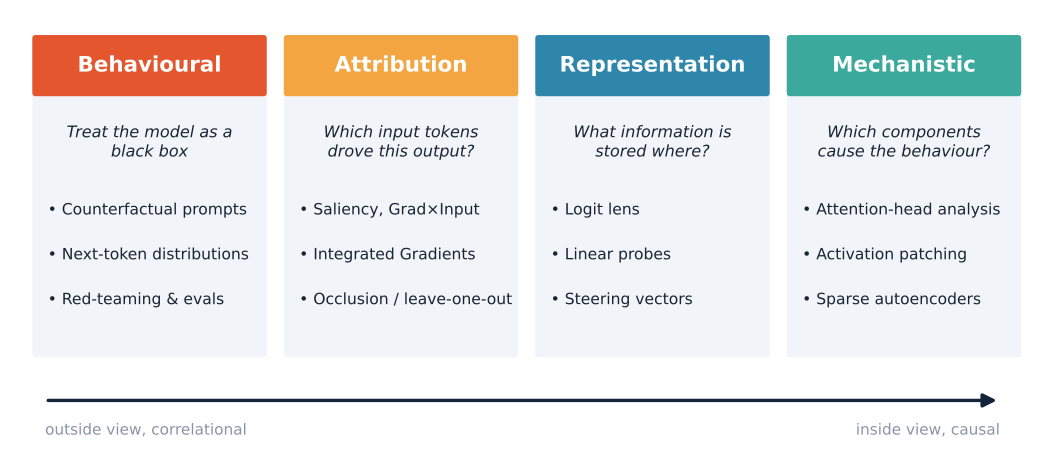

*Figure 1. Four families of methods, ordered from outside-view and correlational to inside-view and causal.*

* **Behavioural** methods probe the model only through its inputs and outputs (counterfactual prompts, output distributions). They need no access to internals but cannot say *how* a behaviour is produced.
* **Attribution** methods assign an importance score to each input token for a given output. They are borrowed from vision/tabular XAI and share its strengths and pitfalls.
* **Representation** methods ask what information is stored in the hidden states (logit lens, probes) and whether we can use that representation to control the model (steering).
* **Mechanistic** methods aim for a causal, component-level account: which heads and MLPs implement an algorithm, verified by interventions such as **activation patching**. Sparse autoencoders try to find the right *units* of analysis (features) for this.

Two distinctions recur throughout the lab:

* **Plausibility vs faithfulness.** An explanation can look convincing to a human (plausible) without reflecting what the model actually computes (faithful). We will test faithfulness explicitly.
* **Correlation vs causation.** A probe that decodes a concept shows the information is *present*, not that the model *uses* it. Interventions (patching, ablation, steering) are needed for causal claims.

## 2. The transformer as a residual stream

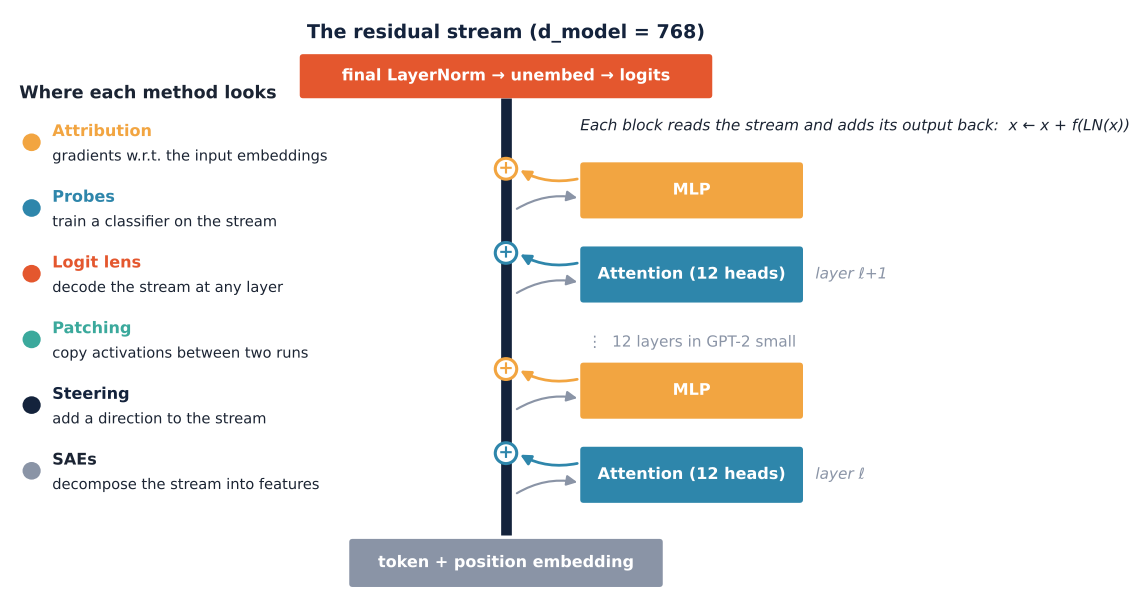

*Figure 2. The residual-stream view (Elhage et al., 2021). Every attention layer and MLP reads from a shared vector per token and **adds** its output back. The stream is the common space in which all methods in this lab operate.*

For a sequence of $T$ tokens the residual stream is a matrix $x \in \mathbb{R}^{T \times d}$ with $d = 768$. Each layer $\ell$ updates it as

$$
x \leftarrow x + \mathrm{Attn}_\ell(\mathrm{LN}(x)), \qquad x \leftarrow x + \mathrm{MLP}_\ell(\mathrm{LN}(x)),
$$

and the final logits are $W_U\,\mathrm{LN}_{\text{final}}(x_T)$. Because updates are **additive**, the final logit can be decomposed into contributions from every component. This is what makes the logit lens, patching and steering possible.

Each attention layer is a sum of $H = 12$ independent heads. Head $h$ computes

$$
\mathrm{head}_h(x) = \mathrm{softmax}\!\left(\frac{(x W_Q^h)(x W_K^h)^\top}{\sqrt{d_{\text{head}}}} + \text{mask}\right) x W_V^h \, W_O^h .
$$

The attention pattern (the softmax) decides **where information is moved from**; the OV circuit $W_V^h W_O^h$ decides **what information is moved**.

### 2.1 Tokens and next-token prediction

Everything an LLM does is next-token prediction. Before explaining it, look at what it predicts.

10 tokens: ['Inter', 'pret', 'ability', ' helps', ' engineers', ' trust', ' large', ' language', ' models', '.']


,token,probability
0,' Paris',0.0638
1,' London',0.0461
2,' Amsterdam',0.0341
3,' New',0.0317
4,' Berlin',0.0262
5,' L',0.0164
6,' E',0.0151
7,' Cologne',0.0146
8,' Hamburg',0.0134
9,' D',0.0125


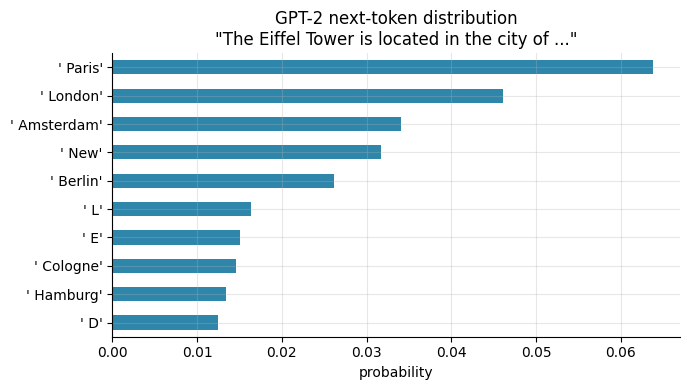

In [5]:
sentence = "Interpretability helps engineers trust large language models."
ids = to_ids(sentence)
print(f"{len(tok_strs(ids))} tokens:", tok_strs(ids))

prompt = "The Eiffel Tower is located in the city of"
table = next_token_table(prompt, k=10)
display(table)

ax = table.iloc[::-1].plot.barh(x="token", y="probability", legend=False, figsize=(7, 4), color="#2E86AB")
ax.set(title=f"GPT-2 next-token distribution\n\"{prompt} ...\"", xlabel="probability", ylabel="")
plt.tight_layout(); plt.show()

**Observation.** Note how *interpretability* is split into several sub-word tokens; explanations are always at the token level, not the word level. The model should put most probability on `' Paris'`. The rest of this lab asks *why*.

> ✍️ **Exercise 2.1.** Try prompts where the model is *wrong* or uncertain (e.g. a less famous landmark, arithmetic such as `"23 + 48 ="`). Keep one failing prompt; you will explain it with every method in the lab.

## 3. Attention patterns

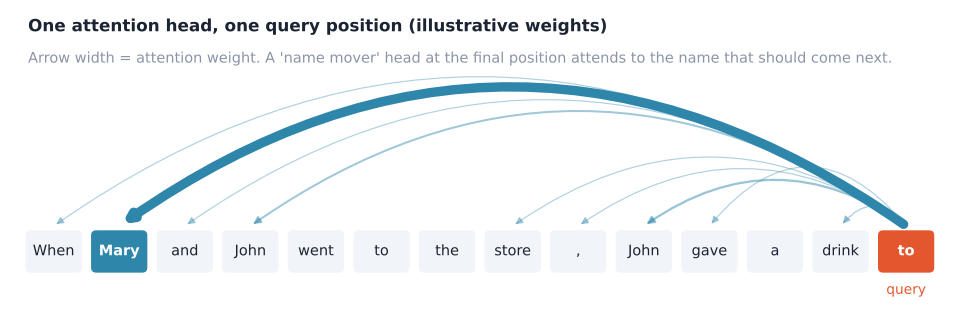

*Figure 3. An attention pattern is a probability distribution, for each query position, over earlier key positions (GPT-2 is causal: no position can look ahead).*

We use the **indirect object identification (IOI)** sentence studied by Wang et al. (2022):

> *"When Mary and John went to the store, John gave a drink to"* → **Mary**

To complete it, the model must notice that *John* is repeated (he is the subject) and output the *other* name. This sentence is used again in the patching section.

,token,probability
0,' Mary',0.4460
1,' them',0.2115
2,' the',0.0711
3,' John',0.0600
4,' her',0.0450


attention tensor: (12, 12, 14, 14)


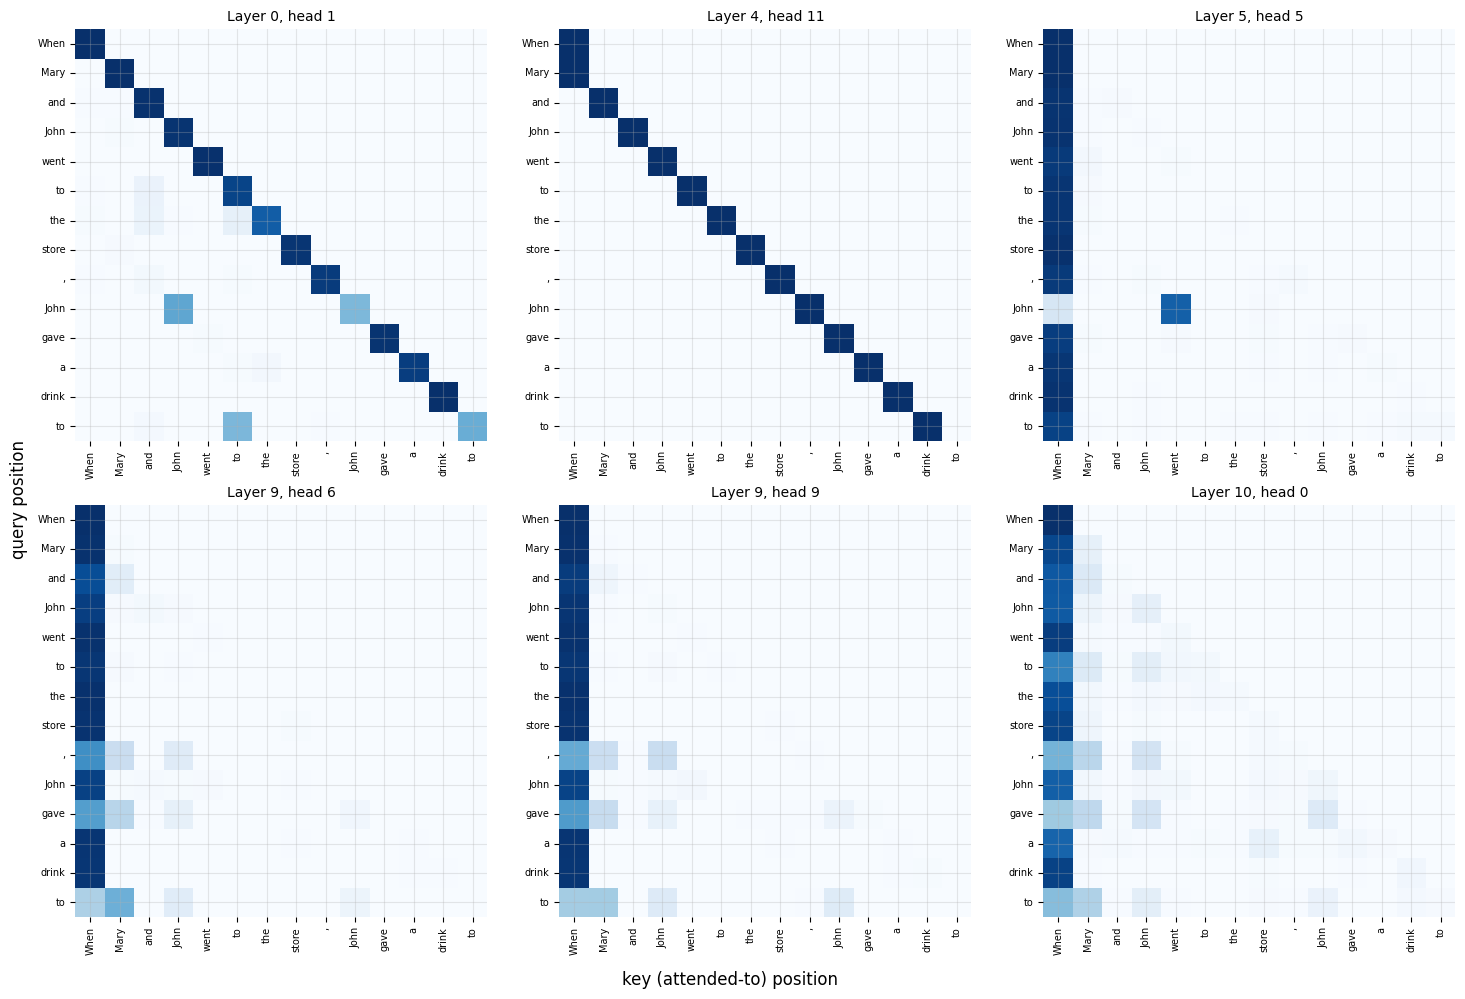

In [6]:
ioi_text = "When Mary and John went to the store, John gave a drink to"
ioi_ids = to_ids(ioi_text)
ioi_toks, ioi_labels = tok_strs(ioi_ids), labels(ioi_ids)
display(next_token_table(ioi_text, k=5))

with torch.no_grad():
    out = model(ioi_ids, output_attentions=True)
attn = torch.stack(out.attentions)[:, 0].cpu()          # (layers, heads, query, key)
print("attention tensor:", tuple(attn.shape))

def plot_attention(A, toks, ax, title):
    A = np.asarray(A)
    sns.heatmap(A, xticklabels=toks, yticklabels=toks, cmap="Blues", vmin=0, vmax=1,
                square=True, cbar=False, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=90, labelsize=7); ax.tick_params(axis="y", rotation=0, labelsize=7)

# A few heads that are known to play distinct roles in GPT-2 small (see text below)
heads = [(0, 1), (4, 11), (5, 5), (9, 6), (9, 9), (10, 0)]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (l, h) in zip(axes.flat, heads):
    plot_attention(attn[l, h], ioi_labels, ax, f"Layer {l}, head {h}")
fig.supxlabel("key (attended-to) position"); fig.supylabel("query position")
plt.tight_layout(); plt.show()

**Reading the plots.** Each row is a query position; each row sums to 1. Patterns you will typically find in GPT-2 small:

* **Previous-token heads** (e.g. 4.11) put almost all weight on the position just before the query: a sharp sub-diagonal.
* **Attention sinks**: many heads dump most of their attention on the *first* token when they have "nothing to do". The first column is bright even though the first word is uninformative (Xiao et al., 2023).
* **Name-mover heads** (e.g. 9.9, 9.6, 10.0 in the IOI paper): in the *last row* (query = `to`) they attend strongly to `Mary`, the name that should be predicted.

Let us look at all 144 heads at once for the last row only: how much does each head, at the final position, attend to the correct name versus the repeated name?

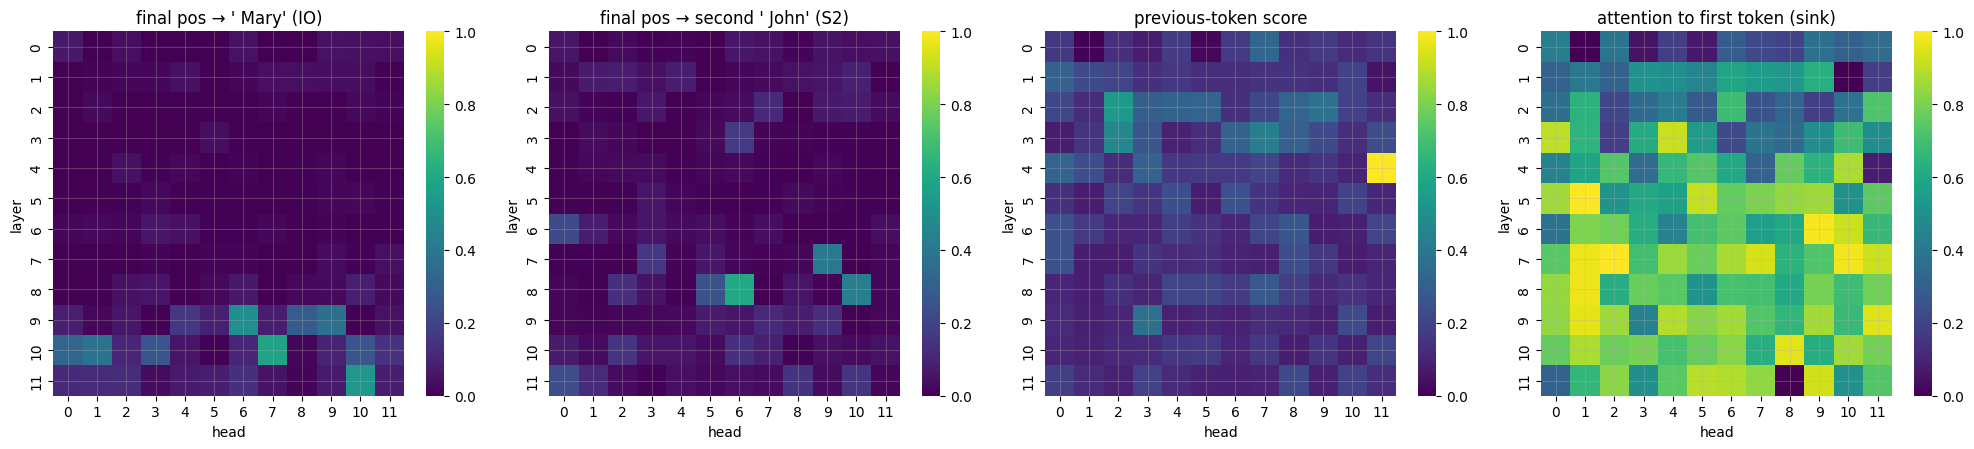

Heads attending most from the final position to ' Mary': ['10.7 (0.58)', '11.10 (0.53)', '9.6 (0.49)', '10.1 (0.38)', '9.9 (0.36)']


In [7]:
io_pos = ioi_toks.index(" Mary")                                   # indirect object
s2_pos = len(ioi_toks) - 1 - ioi_toks[::-1].index(" John")         # second (repeated) subject
to_io = attn[:, :, -1, io_pos].numpy()
to_s2 = attn[:, :, -1, s2_pos].numpy()

T = attn.shape[-1]
prev_tok = torch.stack([attn[:, :, i, i - 1] for i in range(1, T)], -1).mean(-1).numpy()
first_tok = attn[:, :, 1:, 0].mean(-1).numpy()

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, M, title in zip(axes, [to_io, to_s2, prev_tok, first_tok],
                        ["final pos → ' Mary' (IO)", "final pos → second ' John' (S2)",
                         "previous-token score", "attention to first token (sink)"]):
    sns.heatmap(M, cmap="viridis", vmin=0, vmax=1, ax=ax, cbar=True)
    ax.set(title=title, xlabel="head", ylabel="layer")
plt.tight_layout(); plt.show()

top = np.dstack(np.unravel_index(np.argsort(-to_io.ravel())[:5], to_io.shape))[0]
print("Heads attending most from the final position to ' Mary':", [f"{l}.{h} ({to_io[l, h]:.2f})" for l, h in top])

### Is attention an explanation?

Attention maps are attractive because they are free to compute and easy to draw. They are, however, **not** a faithful explanation by themselves:

* Attention says where information is **read from**, not what is read or whether it matters for the output. A head can attend strongly to a token and then write almost nothing (small OV output), or its output can be cancelled downstream.
* Different attention distributions can produce the same prediction (Jain & Wallace, 2019), although carefully designed tests show attention is not *meaningless* either (Wiegreffe & Pinter, 2019).
* Information mixes across positions in every layer. By layer 9, "the `Mary` position" already contains information gathered from other tokens.

Use attention patterns to **generate hypotheses** (e.g. "head 9.9 copies the indirect object"), then test them causally (Section 8).

> ✍️ **Exercise 3.1.** Find the head with the highest *previous-token* score and the head with the highest *attention-sink* score. Plot both patterns on a long sentence of your own. Do they behave the same way?

## 4. Token attribution: which input tokens drove the prediction?

Attribution methods return one score per input token for a chosen output, here the **log-probability of a target token** at the last position. Because tokens are discrete, gradients are taken with respect to the **input embeddings** $e_t \in \mathbb{R}^{768}$ (positional embeddings are added inside the model and kept fixed), and the 768 per-dimension scores are reduced to one number per token.

| Method | Score for token $t$ | Notes |
|---|---|---|
| **Saliency** | $\lVert \nabla_{e_t} f \rVert_2$ | Local sensitivity; unsigned; cheap |
| **Gradient × Input** | $\sum_i e_{t,i}\, \partial f / \partial e_{t,i}$ | First-order Taylor contribution; signed |
| **Integrated Gradients** | $\sum_i (e_{t,i}-e'_{t,i}) \int_0^1 \partial f(e' + \alpha(e - e'))/\partial e_{t,i}\, d\alpha$ | Satisfies **completeness**; needs a baseline $e'$ |
| **Occlusion** (leave-one-out) | $f(e) - f(e \text{ with } e_t \leftarrow e'_t)$ | Model-agnostic; one forward pass per token |

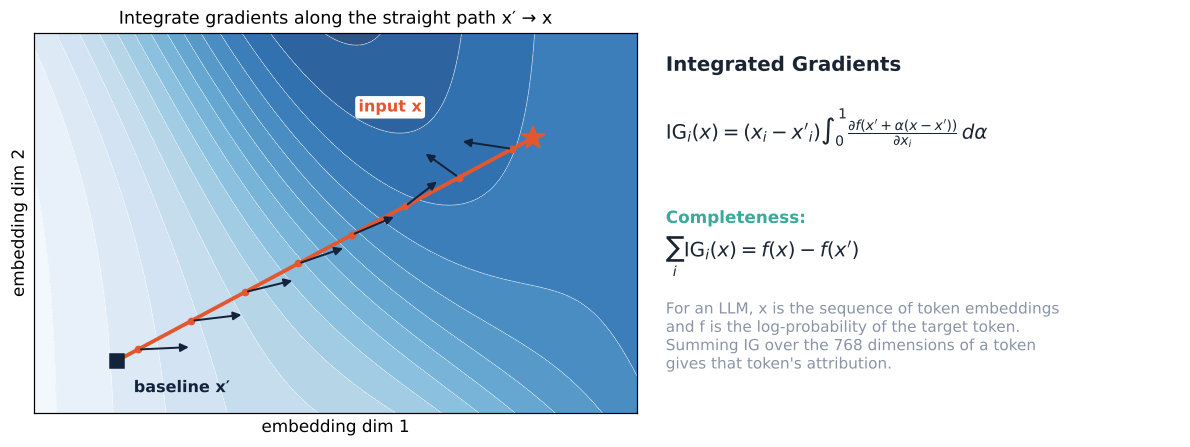

*Figure 4. Integrated Gradients accumulates gradients along a straight path from a baseline to the input. The baseline defines the question: "relative to what?"*

**Baseline choice.** We use a **zero token embedding** (position information kept), i.e. "the same positions with no token identity". Alternatives include the embedding of a padding/`<|endoftext|>` token or the average embedding; changing it changes the explanation (see the exercise).

In [8]:
embed = model.get_input_embeddings()

def token_embeds(ids):
    return embed(ids).detach()                                    # (1, T, d)

def target_logprob(embeds, target_id):
    # f(e): log-probability of the target token at the last position, for a batch of embedding sequences.
    return model(inputs_embeds=embeds).logits[:, -1].log_softmax(-1)[:, target_id]

def _grad(x, target_id):
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(target_logprob(x, target_id).sum(), x)
    return g

def saliency(ids, target_id):
    return _grad(token_embeds(ids), target_id)[0].norm(dim=-1)

def grad_x_input(ids, target_id):
    x = token_embeds(ids)
    return (_grad(x, target_id) * x)[0].sum(-1)

def integrated_gradients(ids, target_id, baseline=None, steps=50):
    x = token_embeds(ids)
    base = torch.zeros_like(x) if baseline is None else baseline
    alphas = (torch.arange(steps, device=x.device) + 0.5) / steps        # midpoint Riemann sum
    path = (base + alphas[:, None, None] * (x - base)).requires_grad_(True)   # (steps, T, d)
    g, = torch.autograd.grad(target_logprob(path, target_id).sum(), path)
    return ((x - base)[0] * g.mean(0)).sum(-1)

@torch.no_grad()
def occlusion(ids, target_id, baseline=None):
    x = token_embeds(ids)
    base = torch.zeros_like(x) if baseline is None else baseline
    T = x.shape[1]
    xs = x.repeat(T, 1, 1)
    idx = torch.arange(T, device=x.device)
    xs[idx, idx] = base[0, idx]                                       # variant t has token t removed
    return target_logprob(x, target_id) - target_logprob(xs, target_id)

METHODS = {"Saliency": saliency, "Gradient×Input": grad_x_input,
           "Integrated Gradients": integrated_gradients, "Occlusion": occlusion}

def attribute(text, target):
    ids, t = to_ids(text), single_token_id(target)
    return ids, t, {name: fn(ids, t).detach().cpu().numpy() for name, fn in METHODS.items()}

def plot_attributions(ids, attrs, title):
    M = np.array([a / (np.abs(a).max() + 1e-12) for a in attrs.values()])
    lab = labels(ids)
    fig, ax = plt.subplots(figsize=(max(9, 0.75 * len(lab)), 0.55 * len(attrs) + 1.6))
    sns.heatmap(M, xticklabels=lab, yticklabels=list(attrs), cmap="RdBu_r", vmin=-1, vmax=1,
                annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax,
                cbar_kws={"label": "attribution / max |attribution|"})
    ax.set_title(title); ax.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

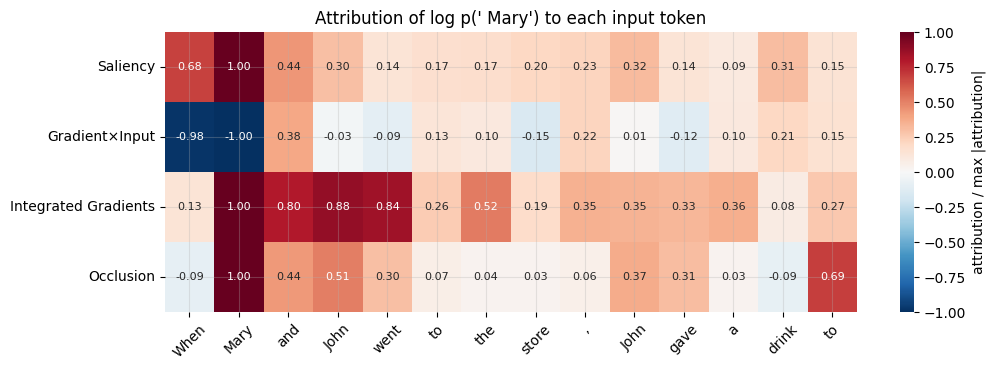

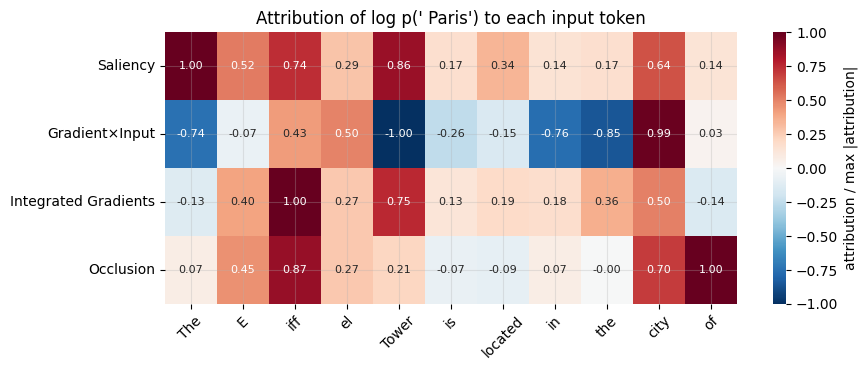

In [9]:
ids, t, attrs = attribute(ioi_text, " Mary")
plot_attributions(ids, attrs, "Attribution of log p(' Mary') to each input token")

ids2, t2, attrs2 = attribute("The Eiffel Tower is located in the city of", " Paris")
plot_attributions(ids2, attrs2, "Attribution of log p(' Paris') to each input token")

**Completeness check.** Integrated Gradients attributions should add up to $f(x) - f(x')$: the change in target log-probability between the real input and the baseline. A large gap means too few integration steps.

In [10]:
for text, target in [(ioi_text, " Mary"), ("The Eiffel Tower is located in the city of", " Paris")]:
    ids_, t_ = to_ids(text), single_token_id(target)
    x = token_embeds(ids_)
    with torch.no_grad():
        delta = (target_logprob(x, t_) - target_logprob(torch.zeros_like(x), t_)).item()
    for steps in [10, 50, 200]:
        s = integrated_gradients(ids_, t_, steps=steps).sum().item()
        print(f"{target!r:9} steps={steps:3d}:  sum(IG) = {s:7.3f}   f(x) - f(x') = {delta:7.3f}   gap = {abs(s - delta):.3f}")

' Mary'   steps= 10:  sum(IG) =  28.401   f(x) - f(x') =  21.857   gap = 6.544
' Mary'   steps= 50:  sum(IG) =  21.872   f(x) - f(x') =  21.857   gap = 0.014
' Mary'   steps=200:  sum(IG) =  21.858   f(x) - f(x') =  21.857   gap = 0.001
' Paris'  steps= 10:  sum(IG) =  27.691   f(x) - f(x') =  18.595   gap = 9.096
' Paris'  steps= 50:  sum(IG) =  18.752   f(x) - f(x') =  18.595   gap = 0.156
' Paris'  steps=200:  sum(IG) =  18.597   f(x) - f(x') =  18.595   gap = 0.002


**Reading the results.**

* For IOI, a sensible explanation gives high positive credit to `Mary` (the answer is copied from there) and highlights the repeated `John`, which tells the model *not* to output John.
* For the Eiffel example, `Tower`/`Eiffel` should dominate, with `city` also contributing.
* **Saliency is unsigned** and often highlights the *last* token (it has the most direct path to the output), which is a reminder that "sensitive" is not the same as "responsible".
* Gradient×Input and IG are signed: blue tokens *lower* the target probability.
* Methods disagree on the details. The next section asks which of them is **faithful**.

> ✍️ **Exercise 4.1.** Change the IG baseline to the embedding of `<|endoftext|>` repeated at every position (`embed(torch.full_like(ids, tok.eos_token_id))`). Which conclusions change? Which stay?
>
> ✍️ **Exercise 4.2.** Attribute the **logit difference** `logit(' Mary') − logit(' John')` instead of `log p(' Mary')`. Why is a contrastive target often more informative?

## 5. Faithfulness: the deletion test

Agreement between methods is not correctness. A **faithful** attribution ranks highly the tokens the model really depends on. The deletion test (most-relevant-first) checks this directly:

1. Rank input tokens by attribution (most supportive first).
2. Replace the top-$k$ token embeddings with the baseline, for $k = 0, 1, \dots, T$.
3. Measure the drop in target log-probability.

A faithful method produces a **steep early drop**. We average over several prompts and compare with a random ranking.

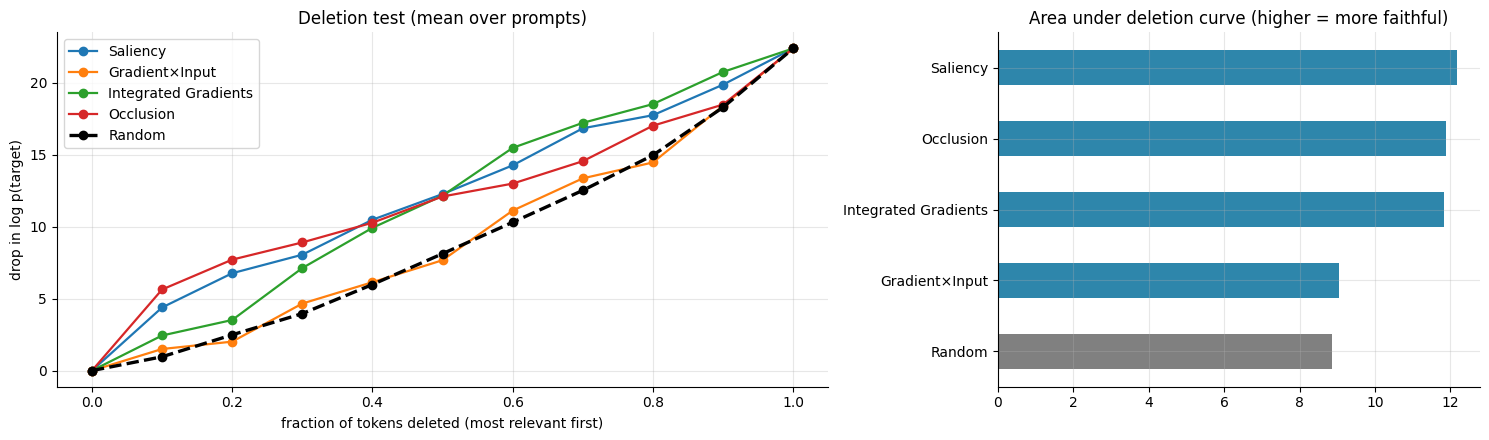

In [11]:
PROMPTS = [
    ("When Mary and John went to the store, John gave a drink to", " Mary"),
    ("The Eiffel Tower is located in the city of", " Paris"),
    ("The capital of Japan is the city of", " Tokyo"),
    ("Yesterday Anna lost her keys, and today she found her", " keys"),
    ("After the long hike, Tom was very hungry, so he ate a big", " meal"),
    ("When Sarah and Tom arrived at the party, Tom handed a gift to", " Sarah"),
]

@torch.no_grad()
def deletion_curve(ids, target_id, order):
    x = token_embeds(ids)
    T = x.shape[1]
    xs = x.repeat(T + 1, 1, 1)
    for k in range(1, T + 1):
        xs[k, order[:k]] = 0.0                     # delete the k most relevant tokens
    return (target_logprob(x, target_id) - target_logprob(xs, target_id)).cpu().numpy()

grid = np.linspace(0, 1, 11)                        # fraction of tokens deleted
curves = {m: [] for m in list(METHODS) + ["Random"]}
rng = np.random.default_rng(SEED)
for text, target in PROMPTS:
    ids, t, attrs = attribute(text, target)
    T = ids.shape[1]
    frac = np.arange(T + 1) / T
    for m, a in attrs.items():
        order = torch.as_tensor(np.argsort(-a).copy(), device=DEVICE)
        curves[m].append(np.interp(grid, frac, deletion_curve(ids, t, order)))
    rand = [np.interp(grid, frac, deletion_curve(ids, t, torch.as_tensor(rng.permutation(T), device=DEVICE)))
            for _ in range(20)]
    curves["Random"].append(np.mean(rand, 0))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
for m, cs in curves.items():
    axes[0].plot(grid, np.mean(cs, 0), marker="o", lw=2.4 if m == "Random" else 1.6,
                 ls="--" if m == "Random" else "-", color="black" if m == "Random" else None, label=m)
axes[0].set(title="Deletion test (mean over prompts)", xlabel="fraction of tokens deleted (most relevant first)",
            ylabel="drop in log p(target)"); axes[0].legend()
trapezoid = getattr(np, "trapezoid", None) or np.trapz          # NumPy 2 renamed trapz
auc = pd.Series({m: trapezoid(np.mean(cs, 0), grid) for m, cs in curves.items()}).sort_values()
auc.plot.barh(ax=axes[1], color=["grey" if m == "Random" else "#2E86AB" for m in auc.index])
axes[1].set(title="Area under deletion curve (higher = more faithful)")
plt.tight_layout(); plt.show()

**Interpretation.**

* Methods that beat the random line identify tokens the model genuinely relies on.
* **Occlusion is trivially good at deletion** because it *is* a deletion measurement for single tokens. Its ranking can still be wrong when tokens matter only in combination.
* Replacing an embedding with zeros creates an **out-of-distribution input**. A large drop might partly reflect "the model is confused by a strange input" rather than "this token carried the answer". Complementary tests include *insertion* (add tokens back to a blank input) and ROAR-style retraining.

> ✍️ **Exercise 5.1.** Implement the **insertion** test (start from the all-baseline input and add tokens most-relevant-first). Do the method rankings agree with the deletion test?

## 6. The logit lens: when does the answer appear?

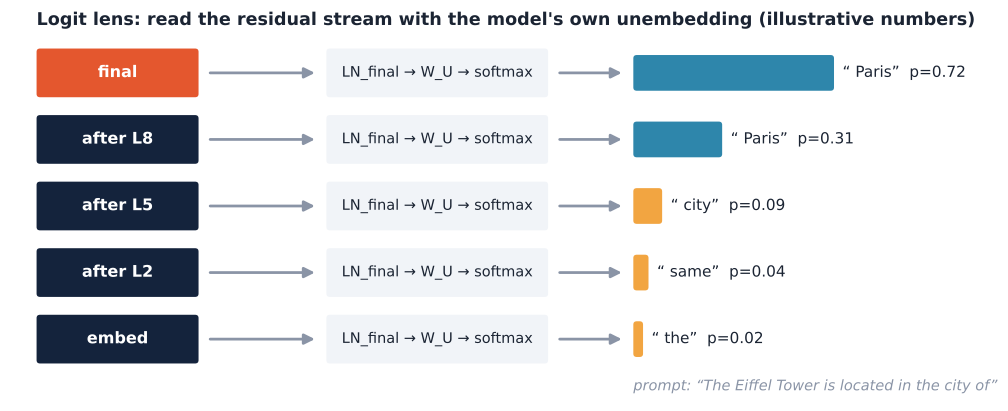

*Figure 5. The logit lens (nostalgebraist, 2020) applies the model's own final LayerNorm and unembedding to the residual stream after each layer, as if the network stopped there.*

Because every layer *adds* to the same stream, intermediate states live in (roughly) the same space as the final one. Decoding them shows how the prediction is assembled layer by layer.

Implementation detail: in Hugging Face GPT-2, `hidden_states[ℓ]` is the stream **entering** block ℓ (`hidden_states[0]` is the embedding), and the **last** entry already has the final LayerNorm applied. We therefore decode `hidden_states[0..11]` with `ln_f` and use the model's real logits for the final row.

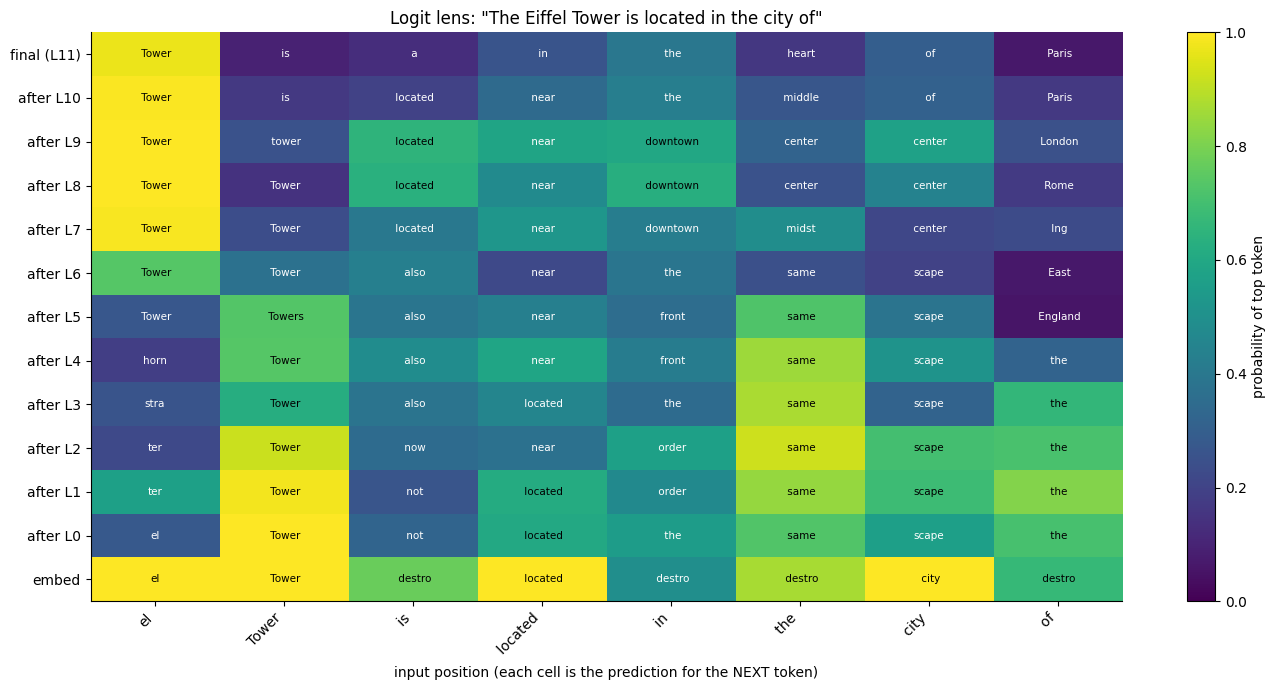

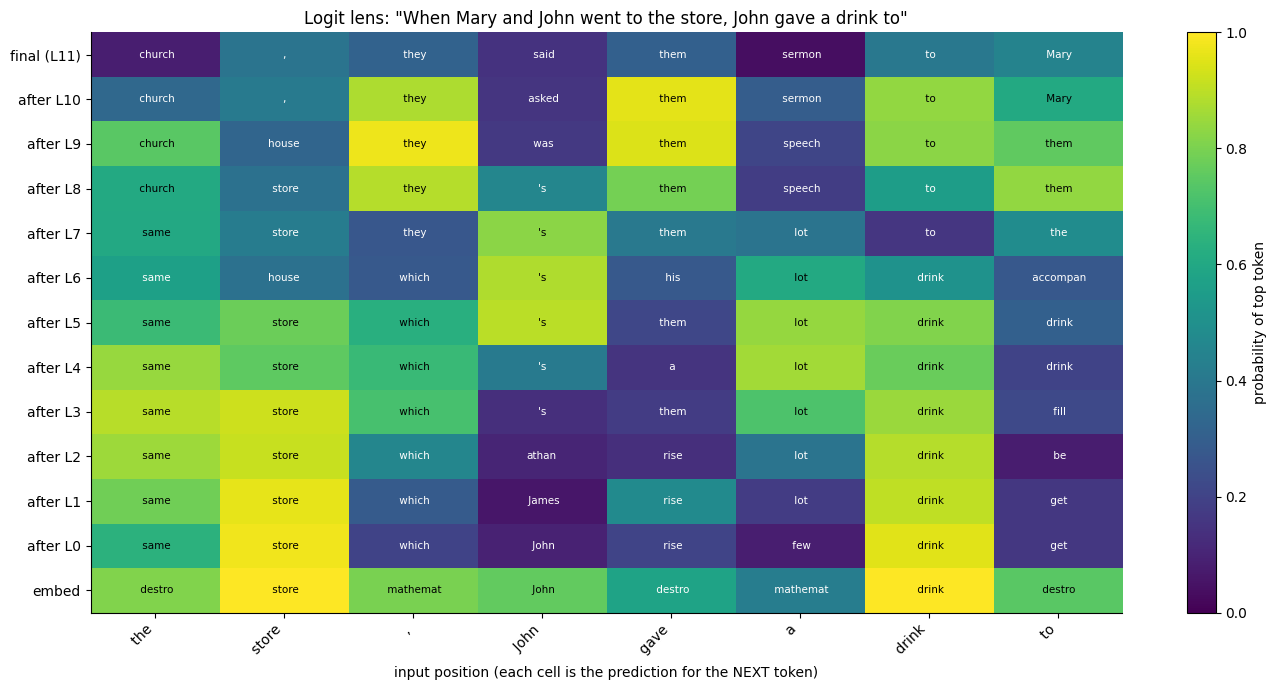

In [12]:
@torch.no_grad()
def logit_lens(text):
    ids = to_ids(text)
    out = model(ids, output_hidden_states=True)
    hs = out.hidden_states
    rows = [model.lm_head(model.transformer.ln_f(hs[l][0])) for l in range(N_LAYERS)]
    rows.append(out.logits[0])
    return ids, torch.stack(rows).softmax(-1).cpu()              # (layers+1, T, vocab)

LENS_LABELS = ["embed"] + [f"after L{l}" for l in range(N_LAYERS - 1)] + [f"final (L{N_LAYERS-1})"]

def plot_logit_lens(text, last_n=8):
    ids, probs = logit_lens(text)
    p = probs[:, -last_n:]
    top_p, top_i = p.max(-1)
    fig, ax = plt.subplots(figsize=(1.5 * last_n + 2, 7))
    im = ax.imshow(top_p, cmap="viridis", vmin=0, vmax=1, aspect="auto", origin="lower")
    for l in range(top_i.shape[0]):
        for j in range(top_i.shape[1]):
            s = repr(tok.decode([top_i[l, j].item()]))[1:-1][:9]
            ax.text(j, l, s, ha="center", va="center", fontsize=7.5, color="white" if top_p[l, j] < 0.6 else "black")
    ax.set_yticks(range(len(LENS_LABELS))); ax.set_yticklabels(LENS_LABELS)
    ax.set_xticks(range(last_n)); ax.set_xticklabels([repr(s)[1:-1] for s in tok_strs(ids)[-last_n:]], rotation=45, ha="right")
    ax.set_xlabel("input position (each cell is the prediction for the NEXT token)"); ax.grid(False)
    fig.colorbar(im, ax=ax, label="probability of top token")
    ax.set_title(f"Logit lens: \"{text}\""); plt.tight_layout(); plt.show()
    return ids, probs

_ = plot_logit_lens("The Eiffel Tower is located in the city of")
_ = plot_logit_lens(ioi_text)

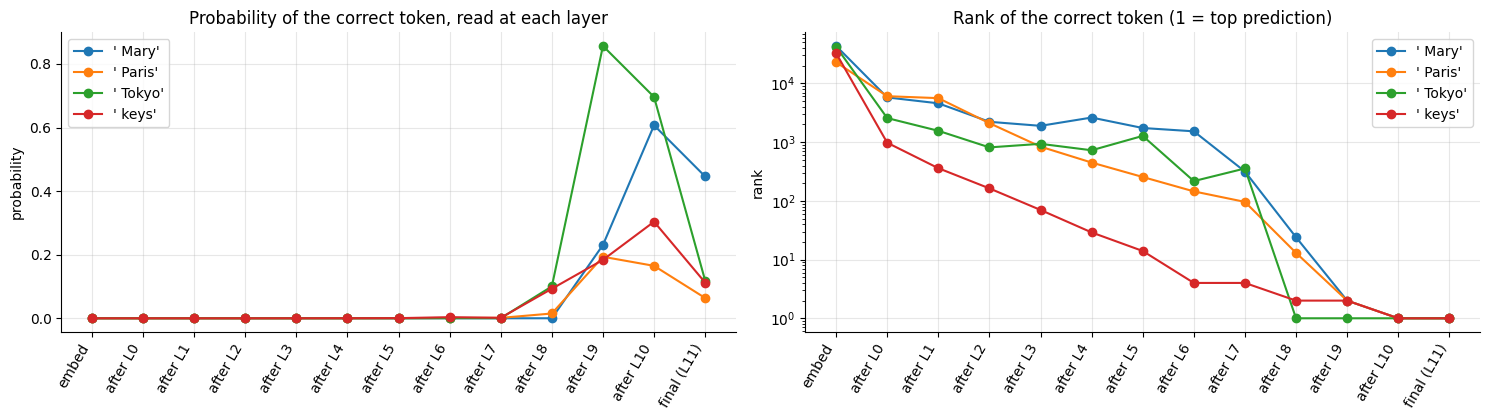

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for text, target in PROMPTS[:4]:
    ids, probs = logit_lens(text)
    t = single_token_id(target)
    p_t = probs[:, -1, t].numpy()
    rank = (probs[:, -1] > probs[:, -1, t:t + 1]).sum(-1).numpy() + 1
    axes[0].plot(range(len(p_t)), p_t, marker="o", label=repr(target))
    axes[1].plot(range(len(rank)), rank, marker="o", label=repr(target))
axes[0].set(title="Probability of the correct token, read at each layer", ylabel="probability")
axes[1].set(title="Rank of the correct token (1 = top prediction)", ylabel="rank", yscale="log")
for ax in axes:
    ax.set_xticks(range(len(LENS_LABELS))); ax.set_xticklabels(LENS_LABELS, rotation=60, ha="right"); ax.legend()
plt.tight_layout(); plt.show()

**What to look for.** In GPT-2 small the correct answer usually climbs into the top ranks only in the **middle-to-late layers**, and its probability rises sharply in the last few blocks. Early layers mostly predict generic continuations (`' the'`, `','`) or echo the input token.

**Caveat.** The logit lens assumes intermediate layers use the same "language" as the final layer. This is only approximately true, especially in early layers and in some model families. The **tuned lens** (Belrose et al., 2023) learns a small affine "translator" per layer and gives more reliable readings.

> ✍️ **Exercise 6.1.** Apply the logit lens to your failing prompt from Exercise 2.1. Does the correct answer appear at some intermediate layer and then get *overwritten*? What might that suggest?

## 7. Linear probing: is a concept decodable, and where?

A **probe** is a simple classifier (here logistic regression) trained to predict a property from the hidden states of a frozen model. Training one probe per layer gives a profile of *where* the information becomes linearly accessible.

Two cautions shape good probing practice (Hewitt & Liang, 2019; Belinkov, 2022):

* A powerful probe can learn the task itself. Keep probes **simple** and regularised, and compare with a **control task** (here: the same inputs with **shuffled labels**). The gap between real and control accuracy (**selectivity**) is what matters.
* High probe accuracy shows information is **present**, not that the model **uses** it. Use interventions for causal claims.

We probe for **sentiment** on 80 short, hand-written sentences (40 positive, 40 negative), using two sentence representations: the **last token** and the **mean over tokens**.

In [14]:
POS = [
 "I absolutely loved this film, it was wonderful.",
 "What a fantastic and uplifting experience.",
 "The food was delicious and the staff were friendly.",
 "This is the best book I have read in years.",
 "She was thrilled with the excellent results.",
 "The concert was amazing from start to finish.",
 "I am so happy with my new phone.",
 "The hotel room was clean, bright and comfortable.",
 "Our holiday was relaxing and beautiful.",
 "The teacher was kind, patient and inspiring.",
 "The new update made the app fast and smooth.",
 "We had a lovely time at the beach.",
 "The garden looks gorgeous in spring.",
 "His speech was brilliant and moving.",
 "This coffee tastes great.",
 "The team played superbly and won easily.",
 "I really enjoyed the museum tour.",
 "The customer service was outstanding.",
 "The puppy is adorable and playful.",
 "It was a delightful evening with friends.",
 "The movie had a charming story and great acting.",
 "I feel grateful and cheerful today.",
 "The design is elegant and practical.",
 "Everyone praised the wonderful performance.",
 "The cake was perfect for the celebration.",
 "This laptop works flawlessly.",
 "The view from the hill was breathtaking.",
 "I would happily recommend this restaurant.",
 "The workshop was useful and fun.",
 "Their wedding was joyful and memorable.",
 "The new park is a pleasant place to walk.",
 "My exam went really well.",
 "The soup was warm, tasty and comforting.",
 "The song is beautiful and uplifting.",
 "He did an excellent job on the project.",
 "The train was punctual and comfortable.",
 "I love the colours in this painting.",
 "Our neighbours are friendly and helpful.",
 "The festival was vibrant and exciting.",
 "This was a truly satisfying meal."
]

NEG = [
 "I absolutely hated this film, it was awful.",
 "What a terrible and depressing experience.",
 "The food was cold and the staff were rude.",
 "This is the worst book I have read in years.",
 "She was upset with the disappointing results.",
 "The concert was boring from start to finish.",
 "I am so unhappy with my new phone.",
 "The hotel room was dirty, dark and uncomfortable.",
 "Our holiday was stressful and miserable.",
 "The teacher was harsh, impatient and dull.",
 "The new update made the app slow and buggy.",
 "We had a horrible time at the beach.",
 "The garden looks ugly and neglected.",
 "His speech was dreadful and tedious.",
 "This coffee tastes bitter and stale.",
 "The team played poorly and lost badly.",
 "I really disliked the museum tour.",
 "The customer service was appalling.",
 "The dog is aggressive and noisy.",
 "It was an unpleasant evening with strangers.",
 "The movie had a confusing story and bad acting.",
 "I feel anxious and gloomy today.",
 "The design is clumsy and impractical.",
 "Everyone criticised the awful performance.",
 "The cake was burnt and ruined the celebration.",
 "This laptop keeps crashing.",
 "The view from the hill was blocked by smog.",
 "I would never recommend this restaurant.",
 "The workshop was useless and dull.",
 "Their wedding was chaotic and stressful.",
 "The new park is a filthy place to walk.",
 "My exam went really badly.",
 "The soup was cold, bland and greasy.",
 "The song is irritating and repetitive.",
 "He did a sloppy job on the project.",
 "The train was late and overcrowded.",
 "I hate the colours in this painting.",
 "Our neighbours are hostile and loud.",
 "The festival was crowded and disappointing.",
 "This was a truly disgusting meal."
]

sentences = POS + NEG
y = np.array([1] * len(POS) + [0] * len(NEG))
print(len(sentences), "sentences")

80 sentences


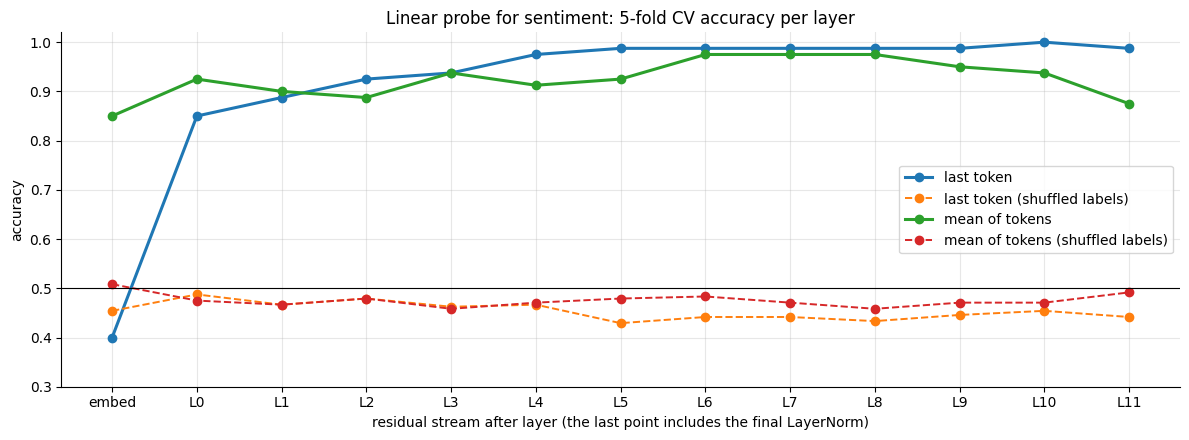

In [15]:
@torch.no_grad()
def sentence_reps(sentences):
    last, mean = [], []
    for s in sentences:
        hs = model(to_ids(s), output_hidden_states=True).hidden_states       # tuple of (1, T, d), length L+1
        H = torch.stack([h[0] for h in hs])                                   # (L+1, T, d)
        last.append(H[:, -1].cpu().numpy())
        mean.append(H.mean(1).cpu().numpy())
    return np.stack(last), np.stack(mean)                                     # (N, L+1, d)

R_last, R_mean = sentence_reps(sentences)

def probe_curve(R, y, seed=SEED):
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000))
    return np.array([cross_val_score(probe, R[:, l], y, cv=cv).mean() for l in range(R.shape[1])])

rng = np.random.default_rng(SEED)
results = {}
for name, R in [("last token", R_last), ("mean of tokens", R_mean)]:
    results[name] = probe_curve(R, y)
    results[name + " (shuffled labels)"] = np.mean([probe_curve(R, rng.permutation(y)) for _ in range(3)], 0)

layer_names = ["embed"] + [f"L{l}" for l in range(N_LAYERS)]
fig, ax = plt.subplots(figsize=(12, 4.5))
for name, acc in results.items():
    ax.plot(layer_names, acc, marker="o", ls="--" if "shuffled" in name else "-", lw=1.4 if "shuffled" in name else 2.2, label=name)
ax.axhline(0.5, color="black", lw=0.8)
ax.set(title="Linear probe for sentiment: 5-fold CV accuracy per layer", ylabel="accuracy", ylim=(0.3, 1.02),
       xlabel="residual stream after layer (the last point includes the final LayerNorm)")
ax.legend(); plt.tight_layout(); plt.show()

**Reading the probe curves.**

* The control curves should hover around 50%: the probe cannot "memorise" random labels well under cross-validation. Real accuracy far above control means sentiment is **linearly decodable**.
* At the embedding layer, the mean-of-tokens probe can already do well because individual sentiment words (*loved*, *awful*) are visible in their own embeddings. The last-token probe (mostly a `.` token) needs the model to **move** sentiment information to that position via attention, so its accuracy typically rises in later layers. That rise is a picture of information flow.
* With only 80 sentences the curves are noisy. Treat differences of a few points as noise.

> ✍️ **Exercise 7.1.** Build a probe for a property that is *not* visible from any single word, such as negation (`"not good"` vs `"good"`) or sarcasm. Where does it become decodable, if anywhere?
>
> ✍️ **Exercise 7.2.** Take the probe's weight vector at a mid layer as a direction and add it to the residual stream (see Section 10). Does it change the model's outputs? (This turns a correlational finding into a causal test.)

## 8. Activation patching: which components cause the behaviour?

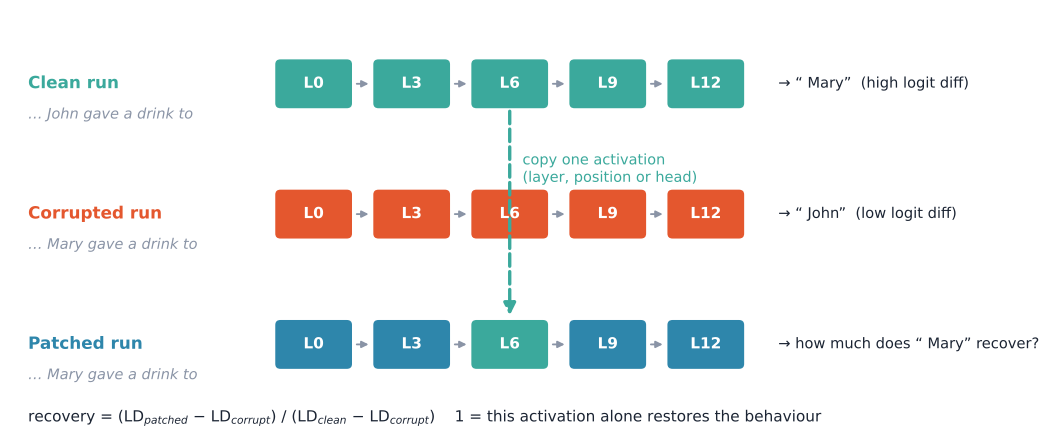

*Figure 6. Activation patching (also called causal tracing or interchange intervention). Run a clean and a corrupted prompt; copy one activation from the clean run into the corrupted run and measure how much of the clean behaviour returns.*

**Setup (IOI).** The clean and corrupted prompts differ in a single token, the second subject:

* clean: *"When Mary and John went to the store, **John** gave a drink to"* → answer **Mary**
* corrupted: *"When Mary and John went to the store, **Mary** gave a drink to"* → answer **John**

**Metric.** Logit difference $\mathrm{LD} = \mathrm{logit}(\text{Mary}) - \mathrm{logit}(\text{John})$ at the last position, normalised so that 0 = corrupted behaviour and 1 = clean behaviour:

$$
\text{recovery} = \frac{\mathrm{LD}_{\text{patched}} - \mathrm{LD}_{\text{corrupt}}}{\mathrm{LD}_{\text{clean}} - \mathrm{LD}_{\text{corrupt}}}.
$$

Patching clean → corrupted (**denoising**) finds components that are *sufficient* to restore the behaviour. The reverse direction (**noising**) finds components that are *necessary*. The two can disagree (Heimersheim & Nanda, 2024).

We use PyTorch **forward hooks** to read and overwrite activations, so every step is explicit. Libraries such as TransformerLens and nnsight package the same idea.

In [16]:
clean_text   = "When Mary and John went to the store, John gave a drink to"
corrupt_text = "When Mary and John went to the store, Mary gave a drink to"
clean_ids, corrupt_ids = to_ids(clean_text), to_ids(corrupt_text)
assert clean_ids.shape == corrupt_ids.shape, "prompts must have the same number of tokens"
MARY, JOHN = single_token_id(" Mary"), single_token_id(" John")

def logit_diff(logits):
    return (logits[0, -1, MARY] - logits[0, -1, JOHN]).item()

# GPT-2 blocks return a tuple (hidden_states, ...) in most transformers versions; handle both cases.
def _hidden(output):
    return output[0] if isinstance(output, tuple) else output

def _with_hidden(output, new):
    return (new,) + tuple(output[1:]) if isinstance(output, tuple) else new

@torch.no_grad()
def run_with_resid_cache(ids):
    cache, handles = {}, []
    for l, block in enumerate(model.transformer.h):
        handles.append(block.register_forward_hook(
            lambda mod, inp, out, l=l: cache.__setitem__(l, _hidden(out).detach().clone())))
    try:
        logits = model(ids).logits
    finally:
        for h in handles: h.remove()
    return logits, cache

@torch.no_grad()
def patched_resid_run(ids, cache, layer, pos):
    def hook(mod, inp, out):
        h = _hidden(out).clone()
        h[:, pos] = cache[layer][:, pos]
        return _with_hidden(out, h)
    handle = model.transformer.h[layer].register_forward_hook(hook)
    try:
        return model(ids).logits
    finally:
        handle.remove()

clean_logits, clean_resid = run_with_resid_cache(clean_ids)
with torch.no_grad():
    corrupt_logits = model(corrupt_ids).logits
LD_CLEAN, LD_CORRUPT = logit_diff(clean_logits), logit_diff(corrupt_logits)
print(f"logit diff (Mary - John):  clean = {LD_CLEAN:.2f}   corrupted = {LD_CORRUPT:.2f}")

logit diff (Mary - John):  clean = 2.01   corrupted = -1.79


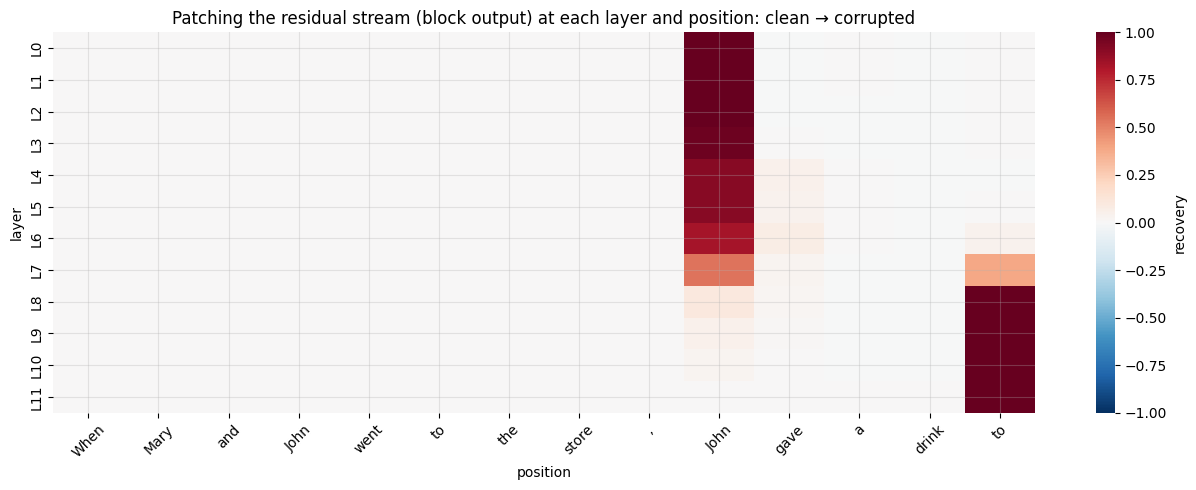

In [17]:
T = clean_ids.shape[1]
resid_recovery = np.zeros((N_LAYERS, T))
for l in range(N_LAYERS):
    for p in range(T):
        ld = logit_diff(patched_resid_run(corrupt_ids, clean_resid, l, p))
        resid_recovery[l, p] = (ld - LD_CORRUPT) / (LD_CLEAN - LD_CORRUPT)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(resid_recovery, cmap="RdBu_r", center=0, vmin=-1, vmax=1, xticklabels=labels(clean_ids),
            yticklabels=[f"L{l}" for l in range(N_LAYERS)], ax=ax, cbar_kws={"label": "recovery"})
ax.set(title="Patching the residual stream (block output) at each layer and position: clean → corrupted",
       xlabel="position", ylabel="layer"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Reading the heatmap.** Positions before the second name are identical in both prompts, so patching them does nothing (white). Typically you will see:

* In **early and middle layers**, recovery is concentrated at the **second `John`** position (S2): the relevant information ("John is repeated") lives there.
* From around **layers 7–9 onwards**, recovery moves to the **final position** (`to`): attention heads have *moved* the information to where the prediction is made.

This "information moving between positions across layers" is the backbone of the IOI circuit. Next we zoom in on individual attention heads at the final position.

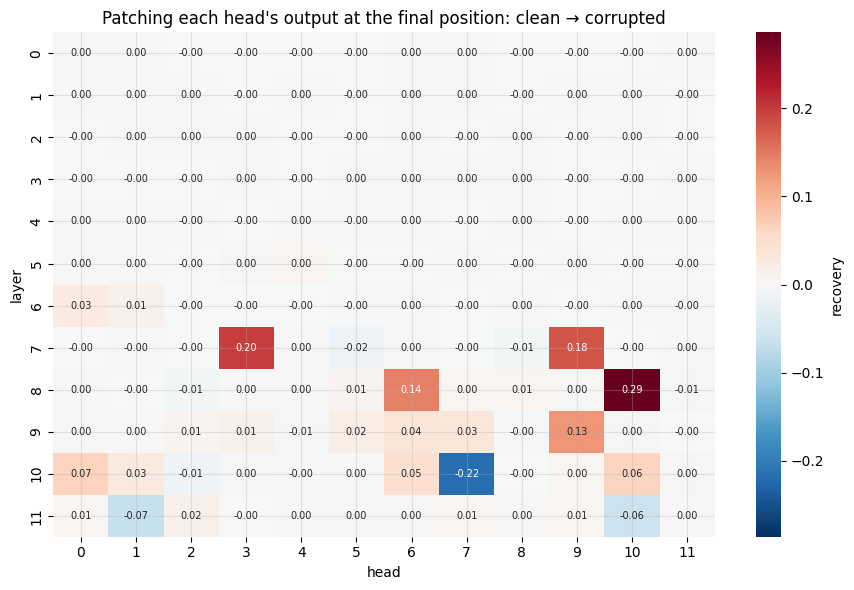

Most important heads: ['8.10 (+0.29)', '10.7 (-0.22)', '7.3 (+0.20)', '7.9 (+0.18)', '8.6 (+0.14)', '9.9 (+0.13)', '10.0 (+0.07)', '11.1 (-0.07)']


In [18]:
# The input to attn.c_proj is the concatenation of all head outputs: head h occupies columns h*D_HEAD:(h+1)*D_HEAD.
@torch.no_grad()
def run_with_head_cache(ids):
    cache, handles = {}, []
    for l, block in enumerate(model.transformer.h):
        handles.append(block.attn.c_proj.register_forward_pre_hook(
            lambda mod, args, l=l: cache.__setitem__(l, args[0].detach().clone())))
    try:
        model(ids)
    finally:
        for h in handles: h.remove()
    return cache

@torch.no_grad()
def patched_head_run(ids, cache, layer, head, pos=-1):
    cols = slice(head * D_HEAD, (head + 1) * D_HEAD)
    def pre_hook(mod, args):
        z = args[0].clone()
        z[:, pos, cols] = cache[layer][:, pos, cols]
        return (z,) + tuple(args[1:])
    handle = model.transformer.h[layer].attn.c_proj.register_forward_pre_hook(pre_hook)
    try:
        return model(ids).logits
    finally:
        handle.remove()

clean_heads = run_with_head_cache(clean_ids)
head_recovery = np.zeros((N_LAYERS, N_HEADS))
for l in range(N_LAYERS):
    for h in range(N_HEADS):
        ld = logit_diff(patched_head_run(corrupt_ids, clean_heads, l, h))
        head_recovery[l, h] = (ld - LD_CORRUPT) / (LD_CLEAN - LD_CORRUPT)

fig, ax = plt.subplots(figsize=(9, 6))
lim = np.abs(head_recovery).max()
sns.heatmap(head_recovery, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "recovery"})
ax.set(title="Patching each head's output at the final position: clean → corrupted", xlabel="head", ylabel="layer")
plt.tight_layout(); plt.show()

order = np.argsort(-np.abs(head_recovery).ravel())[:8]
print("Most important heads:", [f"{l}.{h} ({head_recovery[l, h]:+.2f})" for l, h in zip(*np.unravel_index(order, head_recovery.shape))])

**What the IOI paper found** (Wang et al., 2022), which you can compare with your heatmap:

* **Name-mover heads** (9.9, 9.6, 10.0) attend to the indirect object and copy it into the output: large **positive** recovery.
* **S-inhibition heads** (7.3, 7.9, 8.6, 8.10) tell the name movers *not* to attend to the repeated name.
* **Negative name-mover heads** (10.7, 11.10) push *against* the answer, a kind of calibration: **negative** recovery.

Compare this list with the attention heatmap in Section 3: attention showed us *where* heads look; patching shows which of them **matter**.

> ✍️ **Exercise 8.1.** Repeat head patching in the **noising** direction (patch corrupted activations into the clean run). Which heads are necessary but not sufficient?
>
> ✍️ **Exercise 8.2.** **Ablation.** Replace the output of head 9.9 with its *mean* over a batch of IOI prompts with different names, and measure the drop in logit difference. Why is mean-ablation usually preferred over zero-ablation?

## 9. Induction heads: in-context copying

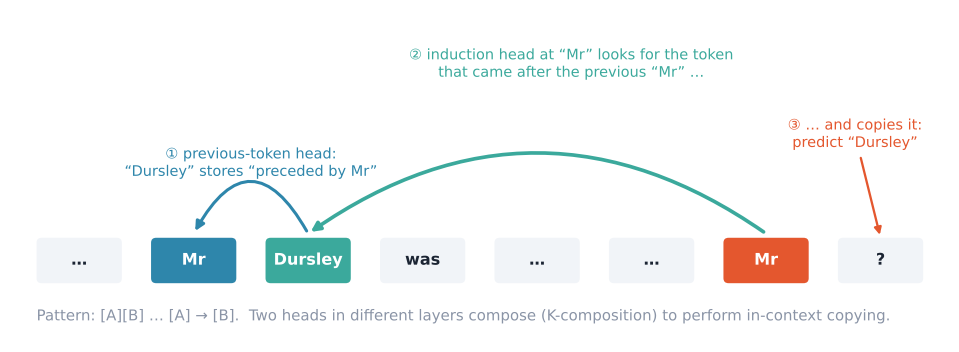

*Figure 7. An induction circuit (Elhage et al., 2021; Olsson et al., 2022). A previous-token head writes "my predecessor was A" into each position; an induction head at a later A searches for that information and copies the token that followed.*

Induction heads are among the best-understood mechanisms in transformers and are thought to underlie much of **in-context learning**. A clean test: feed the model a sequence of **random tokens repeated twice**. The first copy is unpredictable; the second copy is perfectly predictable *only* by copying from context.

mean loss, first copy: 12.01 nats   second copy: 0.20 nats


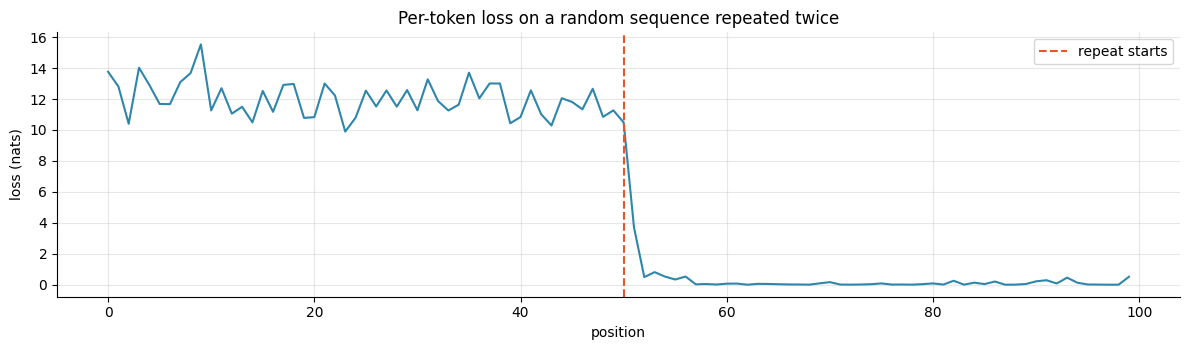

In [19]:
@torch.no_grad()
def repeated_random_tokens(batch=4, n=50, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    rand = torch.randint(1000, 10000, (batch, n), generator=g)
    bos = torch.full((batch, 1), tok.bos_token_id)
    return torch.cat([bos, rand, rand], dim=1).to(DEVICE)          # [BOS, x_1..x_n, x_1..x_n]

N_REP = 50
rep_ids = repeated_random_tokens(n=N_REP)
with torch.no_grad():
    rep_out = model(rep_ids, output_attentions=True)
logp = rep_out.logits.log_softmax(-1)
tok_loss = -logp[:, :-1].gather(-1, rep_ids[:, 1:, None])[..., 0].cpu().numpy()   # loss for predicting token j+1

first, second = tok_loss[:, :N_REP].mean(), tok_loss[:, N_REP + 1:].mean()
print(f"mean loss, first copy: {first:.2f} nats   second copy: {second:.2f} nats")

plt.figure(figsize=(12, 3.6))
plt.plot(tok_loss.mean(0), color="#2E86AB")
plt.axvline(N_REP, color="#E4572E", ls="--", label="repeat starts")
plt.title("Per-token loss on a random sequence repeated twice"); plt.xlabel("position"); plt.ylabel("loss (nats)")
plt.legend(); plt.tight_layout(); plt.show()

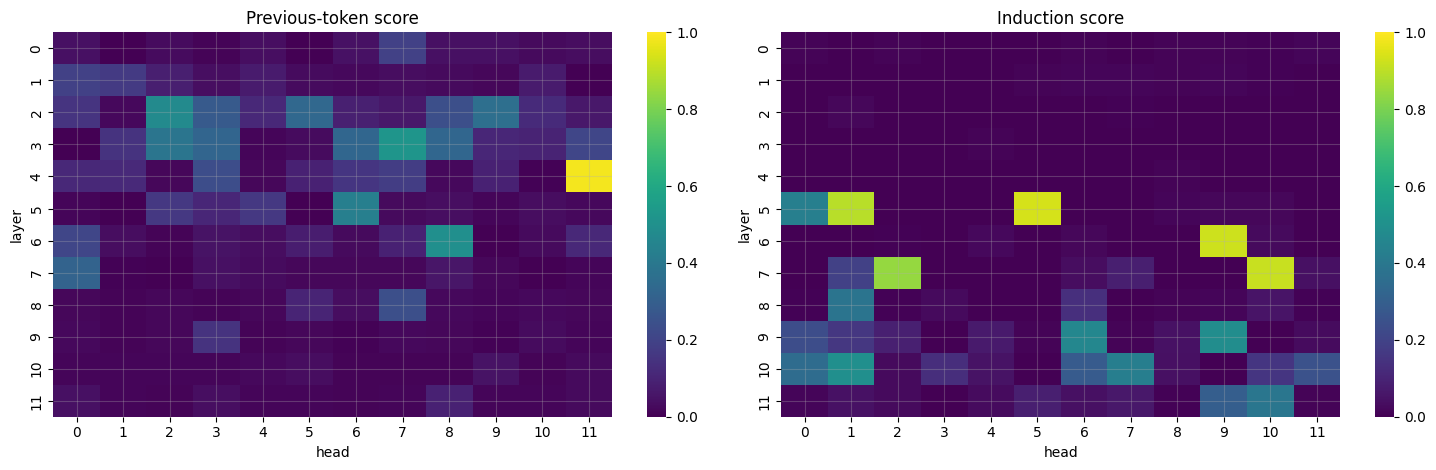

Top induction heads: ['5.5 (0.93)', '6.9 (0.92)', '7.10 (0.91)', '5.1 (0.89)', '7.2 (0.84)', '10.1 (0.49)']


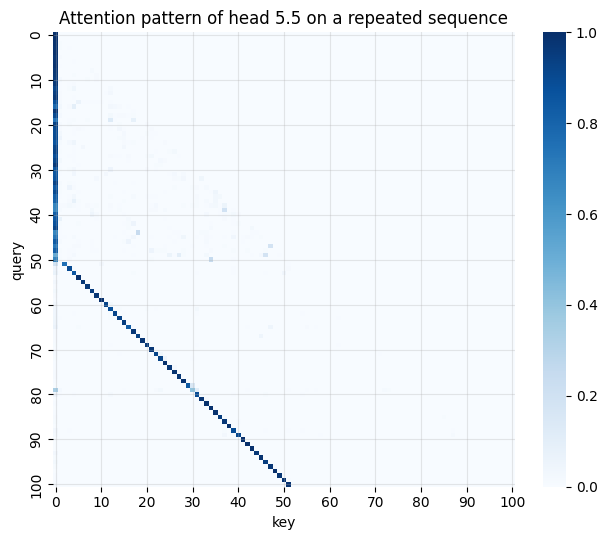

In [20]:
A = torch.stack(rep_out.attentions).cpu()                      # (layers, batch, heads, T, T)
dst = torch.arange(N_REP + 1, 2 * N_REP + 1)                     # positions in the second copy
src = dst - N_REP + 1                                            # the token AFTER the earlier occurrence
induction_score = A[:, :, :, dst, src].mean(dim=(1, 3)).numpy()  # (layers, heads)
prev_dst = torch.arange(2, 2 * N_REP + 1)
prev_score = A[:, :, :, prev_dst, prev_dst - 1].mean(dim=(1, 3)).numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, M, title in [(axes[0], prev_score, "Previous-token score"), (axes[1], induction_score, "Induction score")]:
    sns.heatmap(M, cmap="viridis", vmin=0, vmax=1, ax=ax); ax.set(title=title, xlabel="head", ylabel="layer")
plt.tight_layout(); plt.show()

top = np.argsort(-induction_score.ravel())[:6]
top_heads = list(zip(*np.unravel_index(top, induction_score.shape)))
print("Top induction heads:", [f"{l}.{h} ({induction_score[l, h]:.2f})" for l, h in top_heads])

l, h = top_heads[0]
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(A[l, 0, h].numpy(), cmap="Blues", vmin=0, vmax=1, xticklabels=10, yticklabels=10)
plt.title(f"Attention pattern of head {l}.{h} on a repeated sequence"); plt.xlabel("key"); plt.ylabel("query")
plt.tight_layout(); plt.show()

**What to expect.** The loss drops sharply in the second copy: the model copies from context. Induction scores near 1 typically appear in heads in **layers 5–7** (e.g. 5.1, 5.5, 6.9, 7.2, 7.10 in GPT-2 small), while strong previous-token heads appear **earlier** (e.g. 4.11). The top head's pattern shows a stripe offset by $n-1$ from the diagonal: each token in the second copy attends to the token *after* its earlier occurrence.

> ✍️ **Exercise 9.1.** Mean-ablate the top induction heads (Section 8 hooks) and re-measure the second-copy loss. How much of the in-context copying do they account for?

## 10. Steering vectors: control through representations

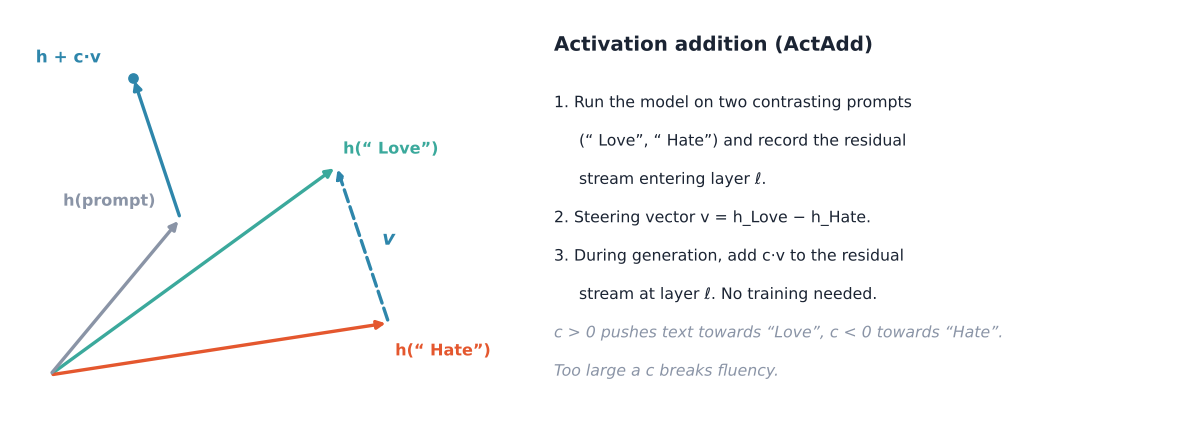

*Figure 8. Activation addition (Turner et al., 2023). The difference between activations for two contrasting prompts gives a direction; adding it during generation shifts the output.*

If a concept is represented as a **direction** in the residual stream, adding that direction should change behaviour. That makes steering a **causal test** of a representational hypothesis, and a practical control technique (see also representation engineering, Zou et al., 2023).

In [21]:
@torch.no_grad()
def resid_entering(text, layer):
    ids = torch.cat([torch.tensor([[tok.bos_token_id]], device=DEVICE), to_ids(text)], dim=1)
    return model(ids, output_hidden_states=True).hidden_states[layer][0, -1]

STEER_LAYER = 6
steer = resid_entering(" Love", STEER_LAYER) - resid_entering(" Hate", STEER_LAYER)
with torch.no_grad():
    typical = model(to_ids("I think my neighbour is"), output_hidden_states=True).hidden_states[STEER_LAYER][0, 1:].norm(dim=-1).mean()
print(f"|steering vector| = {steer.norm():.1f}   typical |residual| at layer {STEER_LAYER} = {typical:.1f}")

def add_steering(vec, layer, coef):
    # Forward pre-hook on block `layer`: adds coef * vec to the residual stream entering it, at every position.
    coef = float(coef)
    def pre_hook(mod, args, kwargs):
        if args:
            return (args[0] + coef * vec,) + tuple(args[1:]), kwargs
        kwargs = dict(kwargs); kwargs["hidden_states"] = kwargs["hidden_states"] + coef * vec
        return args, kwargs
    return model.transformer.h[layer].register_forward_pre_hook(pre_hook, with_kwargs=True)

def generate(prompt, coef=0.0, n=3, max_new_tokens=30):
    handle = add_steering(steer, STEER_LAYER, coef) if coef else None
    try:
        ids = to_ids(prompt)
        outs = []
        for s in range(n):
            torch.manual_seed(SEED + s)
            g = model.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=max_new_tokens,
                               do_sample=True, top_p=0.9, temperature=0.8, pad_token_id=tok.eos_token_id)
            outs.append(tok.decode(g[0, ids.shape[1]:]).replace("\n", " "))
        return outs
    finally:
        if handle is not None:
            handle.remove()

prompt = "I think my neighbour is"
for coef in [-8, 0, 8]:
    print(f"\n=== coefficient {coef:+d} ===")
    for s in generate(prompt, coef):
        print(textwrap.fill(prompt + s, 110))

|steering vector| = 45.0   typical |residual| at layer 6 = 82.5

=== coefficient -8 ===
I think my neighbour is Hepllicpllicplplolpl [licliclicliclicpllic liclic liclicpl (plliclic. and
I think my neighbour is real.plliclic:plhead.pl.pllic.lic.lic.pllic.pl "plplpl:pl ' white
I think my neighbour is real war-man and grouppl.  Heplplliclic 'plplpl:liclic, (plpl 'liclicliclic

=== coefficient +0 ===
I think my neighbour is too."  "They're really scared to leave," said Mr Lee. "I've never seen them at home
before."  Mr Lee
I think my neighbour is a very smart guy and he's been here for a long time. I am glad to see him. He's had a
lot of experience.
I think my neighbour is going to be very upset if I go out there with him," said Mr. Dickson, whose family
runs a small food service business. "I

=== coefficient +8 ===
I think my neighbour is for you!! it!!! our!! LOVE Love amazing!~ LOVE! LOVE LOVE!! LOVE LOVE!!! LOVE!!! LOVE!
love amazing
I think my neighbour is always with LOVE with  LOVE 

Generations are noisy, so let us also measure the effect: the average log-probability of positive versus negative next words over several prompts, as the steering coefficient varies.

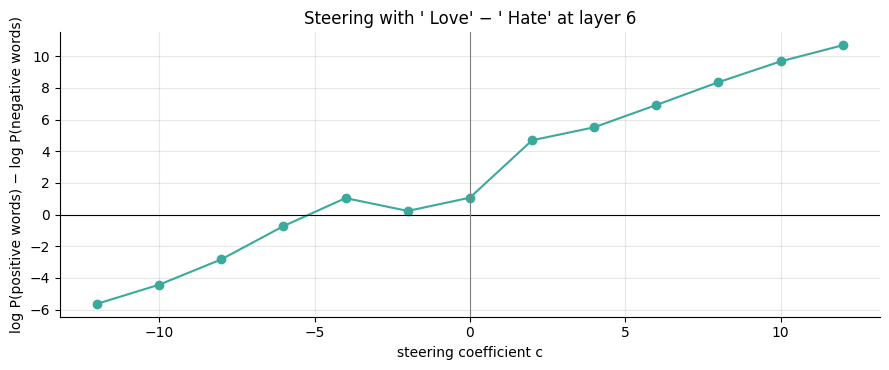

In [22]:
POS_W = [single_token_id(w) for w in [" wonderful", " great", " happy", " love", " good"]]
NEG_W = [single_token_id(w) for w in [" terrible", " awful", " sad", " hate", " bad"]]
STEER_PROMPTS = ["I think my neighbour is", "The movie was", "Today I feel", "My boss is really", "The food at this place is"]

@torch.no_grad()
def sentiment_score(coef):
    handle = add_steering(steer, STEER_LAYER, coef) if coef else None
    try:
        vals = []
        for p in STEER_PROMPTS:
            lp = model(to_ids(p)).logits[0, -1].log_softmax(-1)
            vals.append((lp[POS_W].logsumexp(0) - lp[NEG_W].logsumexp(0)).item())
        return np.mean(vals)
    finally:
        if handle is not None:
            handle.remove()

coefs = list(range(-12, 13, 2))
scores = [sentiment_score(c) for c in coefs]
plt.figure(figsize=(9, 3.8))
plt.plot(coefs, scores, marker="o", color="#3BA99C"); plt.axhline(0, color="black", lw=0.8); plt.axvline(0, color="grey", lw=0.8)
plt.title(f"Steering with ' Love' − ' Hate' at layer {STEER_LAYER}")
plt.xlabel("steering coefficient c"); plt.ylabel("log P(positive words) − log P(negative words)")
plt.tight_layout(); plt.show()

**Interpretation.** A monotone curve means the direction causally controls a sentiment-like property of the next token. Very large coefficients push the residual stream far off-distribution and fluency collapses (try `coef=40`).

> ✍️ **Exercise 10.1.** Vary `STEER_LAYER` from 0 to 11. At which layers is steering most effective? Relate this to the probe curve in Section 7.
>
> ✍️ **Exercise 10.2.** Build a steering vector from *many* contrast pairs (e.g. the mean difference between the POS and NEG sentence representations from Section 7) instead of one word pair. Is it more reliable?

## 11. Sparse autoencoders: finding the model's features

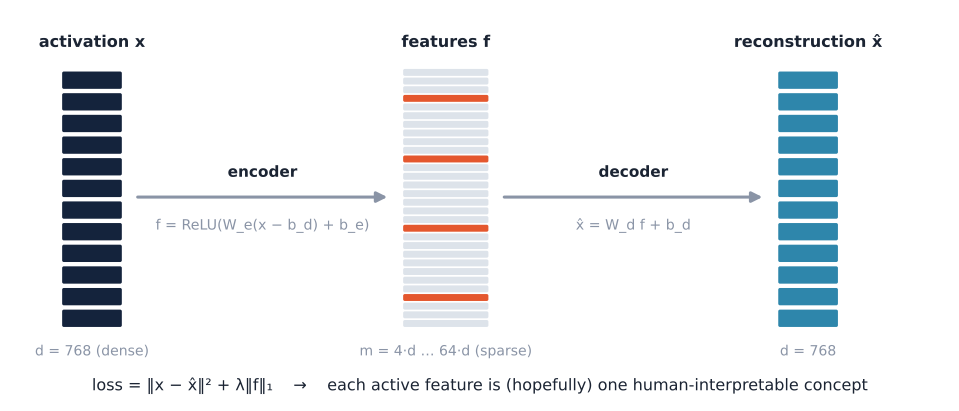

*Figure 9. A sparse autoencoder (SAE) rewrites each activation vector as a sparse, non-negative combination of many learned feature directions.*

**Why not just look at neurons?** Individual neurons are often **polysemantic**: one neuron fires for unrelated concepts. The **superposition hypothesis** (Elhage et al., 2022) explains why: a model can represent *more* features than it has dimensions by storing them as nearly-orthogonal directions, as long as features are sparse. SAEs try to undo superposition by learning an **overcomplete** dictionary in which each activation uses only a few features (Bricken et al., 2023; Cunningham et al., 2023). Frontier-scale SAEs have found millions of interpretable features (Templeton et al., 2024).

Below we train a **small** SAE on layer-6 residual activations from up to 40k tokens of WikiText-2 (falling back to a short built-in corpus when offline). It runs in a few minutes on a CPU. The features will be rougher than those of research SAEs trained on hundreds of millions of tokens, but you can see the full pipeline: collect activations → train with an L1 sparsity penalty → check reconstruction and sparsity → inspect top-activating tokens.

In [23]:
CORPUS = [
 "The monsoon reached Kerala in early June, bringing heavy rain to the coast. Farmers in the region depend on the rainfall to plant rice, and the India Meteorological Department publishes daily forecasts during the season.",
 "In 1969, Neil Armstrong and Buzz Aldrin landed on the Moon while Michael Collins orbited above in the command module. The mission returned safely to Earth eight days after launch.",
 "To make a simple dal, rinse one cup of lentils, boil them with turmeric and salt, and finish with a tempering of cumin seeds, garlic and dried red chillies fried in ghee.",
 "def fibonacci(n):\n    if n < 2:\n        return n\n    return fibonacci(n - 1) + fibonacci(n - 2)\n\nfor i in range(10):\n    print(i, fibonacci(i))",
 "The Reserve Bank kept the repo rate unchanged at its latest meeting, citing stable inflation and steady growth. Bond yields fell slightly after the announcement, and the rupee closed higher against the dollar.",
 "Virat Kohli scored a century as India chased down the target with four overs to spare. The bowlers had earlier restricted the visitors to 251 for 8 on a slow pitch in Bengaluru.",
 "Photosynthesis converts light energy into chemical energy. In the chloroplasts, water is split and carbon dioxide is fixed into glucose, releasing oxygen as a by-product.",
 "Dear Professor Rao, thank you for your detailed feedback on my thesis draft. I have revised the second chapter and added the experiments you suggested. Kind regards, Priya.",
 "The train from Chennai to Mumbai departs at 6:45 in the morning and arrives the next day at 11:30. Passengers are advised to carry a valid photo ID along with their tickets.",
 "Transformers process all tokens in parallel using self-attention. Each layer contains attention heads and a multilayer perceptron, connected by residual connections and layer normalisation.",
 "Once upon a time, a clever crow found a pitcher with very little water. She dropped pebbles into it one by one until the water rose high enough for her to drink.",
 "The Taj Mahal in Agra was commissioned in 1632 by the emperor Shah Jahan. Built from white marble, it attracts millions of visitors every year and is a UNESCO World Heritage Site.",
 "SELECT name, salary FROM employees WHERE department = 'Research' ORDER BY salary DESC LIMIT 10;",
 "Symptoms of dehydration include thirst, dizziness and dark urine. Drinking water regularly, especially during hot weather and exercise, helps the body regulate its temperature.",
 "On Monday the temperature was 31 degrees, on Tuesday 33 degrees and on Wednesday 35 degrees. Forecasters expect the heatwave to continue until the weekend, when thunderstorms may bring relief.",
 "The theorem states that every bounded monotone sequence of real numbers converges. The proof uses the completeness axiom: the supremum of the sequence is its limit.",
 "Our startup is hiring a machine learning engineer with experience in PyTorch, distributed training and model evaluation. Please send your CV and a short cover letter to the hiring team.",
 "Shakespeare wrote Hamlet around 1600. The play follows Prince Hamlet as he seeks revenge on his uncle Claudius, who murdered Hamlet's father and married his mother, Gertrude."
]

# A larger corpus gives much better features. WikiText-2 is downloaded from the Hugging Face Hub;
# if that fails (offline), the small built-in corpus above is used instead.
USE_WIKITEXT = True
if USE_WIKITEXT:
    try:
        from datasets import load_dataset
        wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
        CORPUS = [t for t in wiki["text"] if len(t) > 200][:600]
    except Exception as e:
        print("WikiText not available, using the built-in corpus:", type(e).__name__)
print(len(CORPUS), "documents")

README.md: 0.00B [00:00, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

wikitext-2-raw-v1/validation-00000-of-00(…):   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

600 documents


In [24]:
SAE_LAYER, CHUNK = 6, 64

@torch.no_grad()
def collect_activations(texts, layer=SAE_LAYER, chunk=CHUNK, max_tokens=40_000):
    acts, contexts = [], []
    for text in texts:
        ids = to_ids(text)[:, :1024]
        for s in range(0, ids.shape[1], chunk):
            piece = ids[:, s:s + chunk]
            if piece.shape[1] < 4:
                continue
            h = model(piece, output_hidden_states=True).hidden_states[layer][0]   # (t, d)
            # Drop position 0: GPT-2's first position has an outlier norm (attention sink) that dominates training.
            acts.append(h[1:].cpu())
            pl = piece[0].tolist()
            contexts += [(pl, j) for j in range(1, len(pl))]
            if sum(len(a) for a in acts) >= max_tokens:
                return torch.cat(acts), contexts
    return torch.cat(acts), contexts

acts, contexts = collect_activations(CORPUS)
mu = acts.mean(0)
scale = (acts - mu).norm(dim=-1).mean() / math.sqrt(D_MODEL)
X = ((acts - mu) / scale).to(DEVICE)                 # centred, scaled so E||x|| = sqrt(d)
print("activations:", tuple(X.shape))

activations: (40031, 768)


fraction of variance explained = 0.870 | mean active features per token (L0) = 121.1 | dead features = 0.0%


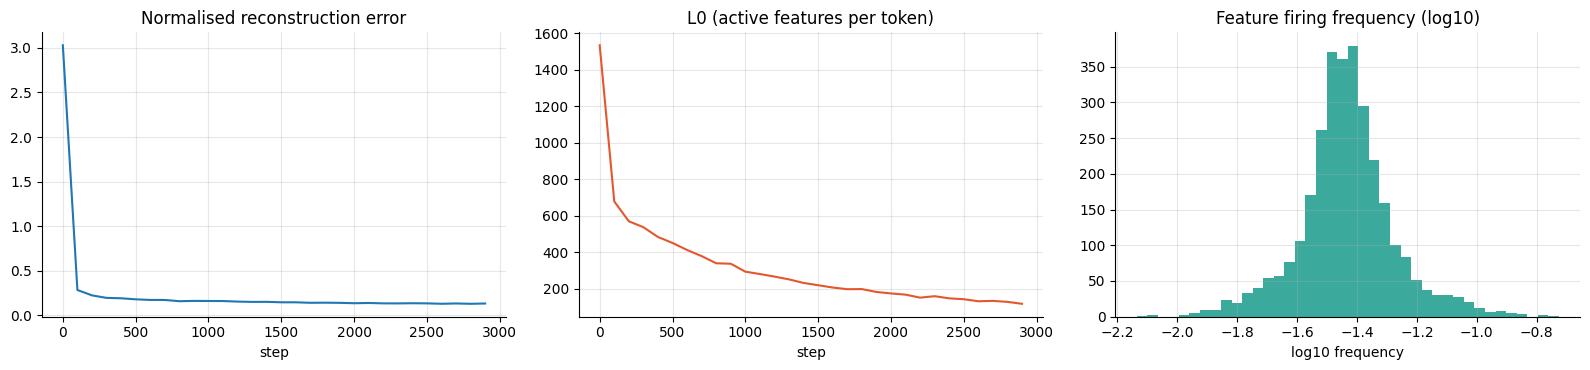

In [25]:
class SparseAutoencoder(nn.Module):
    def __init__(self, d, m):
        super().__init__()
        W = torch.randn(m, d)
        W = W / W.norm(dim=1, keepdim=True)
        self.W_dec = nn.Parameter(W.clone())              # (m, d): one unit-norm direction per feature
        self.W_enc = nn.Parameter(W.T.clone())            # (d, m)
        self.b_enc = nn.Parameter(torch.zeros(m))
        self.b_dec = nn.Parameter(torch.zeros(d))

    def encode(self, x):
        return torch.relu((x - self.b_dec) @ self.W_enc + self.b_enc)

    def forward(self, x):
        f = self.encode(x)
        return f @ self.W_dec + self.b_dec, f

    @torch.no_grad()
    def normalise_decoder(self):
        self.W_dec.data /= self.W_dec.data.norm(dim=1, keepdim=True)

torch.manual_seed(SEED)
# With the tiny built-in corpus (< 1k tokens) a small dictionary and short training avoid pure memorisation.
EXPANSION, STEPS = (4, 3000) if len(X) > 10_000 else (1, 500)
L1_COEF, BATCH = 1.0, 256
sae = SparseAutoencoder(D_MODEL, EXPANSION * D_MODEL).to(DEVICE)
opt = torch.optim.Adam(sae.parameters(), lr=1e-3)
history = []
for step in range(STEPS):
    xb = X[torch.randint(0, len(X), (BATCH,), device=DEVICE)]
    x_hat, f = sae(xb)
    mse = ((x_hat - xb) ** 2).sum(-1).mean()
    l1 = f.abs().sum(-1).mean()
    loss = mse + L1_COEF * l1
    opt.zero_grad(); loss.backward(); opt.step(); sae.normalise_decoder()
    if step % 100 == 0:
        history.append((step, mse.item() / (xb ** 2).sum(-1).mean().item(), (f > 0).float().sum(-1).mean().item()))

with torch.no_grad():
    x_hat, F_all = sae(X)
    fve = 1 - ((x_hat - X) ** 2).sum() / ((X - X.mean(0)) ** 2).sum()
    l0 = (F_all > 0).float().sum(-1).mean()
    freq = (F_all > 0).float().mean(0).cpu().numpy()
print(f"fraction of variance explained = {fve:.3f} | mean active features per token (L0) = {l0:.1f} | "
      f"dead features = {(freq == 0).mean():.1%}")

h = np.array(history)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(h[:, 0], h[:, 1]); axes[0].set(title="Normalised reconstruction error", xlabel="step")
axes[1].plot(h[:, 0], h[:, 2], color="#E4572E"); axes[1].set(title="L0 (active features per token)", xlabel="step")
axes[2].hist(np.log10(freq[freq > 0]), bins=40, color="#3BA99C"); axes[2].set(title="Feature firing frequency (log10)", xlabel="log10 frequency")
plt.tight_layout(); plt.show()

**Tuning the SAE.** The L1 coefficient trades reconstruction against sparsity. If L0 is below about 5 and the explained variance is poor, lower `L1_COEF`; if L0 is above about 100, raise it. Many **dead features** (never active) are common with little data. Real SAEs are trained on hundreds of millions of tokens with techniques such as resampling dead features or TopK/JumpReLU activations.

Now inspect what a few features respond to. For each feature, we show the tokens where it fires most strongly, with the firing token in **[[ ]]** and some left context.

In [26]:
def show_feature(i, k=5, left=8):
    vals, idx = F_all[:, i].topk(k)
    print(f"\n--- feature {i}  (fires on {freq[i]:.2%} of tokens) ---")
    for v, j in zip(vals.tolist(), idx.tolist()):
        if v <= 0:
            break
        ids, pos = contexts[j]
        ctx = tok.decode(ids[max(0, pos - left):pos]).replace("\n", "⏎")
        cur = tok.decode([ids[pos]]).replace("\n", "⏎")
        nxt = tok.decode(ids[pos + 1:pos + 3]).replace("\n", "⏎")
        print(f"  {v:6.2f}  …{ctx}[[{cur}]]{nxt}…")

candidates = np.where((freq > 0.002) & (freq < 0.05))[0]
if len(candidates) == 0:                       # fallback if the sparsity setting is far off
    candidates = np.where(freq > 0)[0]
strength = F_all.max(0).values.cpu().numpy()
for i in candidates[np.argsort(-strength[candidates])][:8]:
    show_feature(int(i))


--- feature 503  (fires on 1.69% of tokens) ---
   25.04  … and fully understand their mysterious nature . [[⏎]]…
   24.78  … divine when he was performing ceremonies . [[⏎]]…
   24.62  … to more indirect means of communication . [[⏎]]…
   24.60  … ' help for their personal problems . [[⏎]]…
   24.56  … was more important than elaborate storytelling . [[⏎]]…

--- feature 2894  (fires on 1.49% of tokens) ---
   24.99  … Science and Natural History merged with the Little[[ Rock]] Children '…
   24.48  … second floor of the Tower Building became Little[[ Rock]] 's…
   24.46  … Infantry Regiments mustered in at Little[[ Rock]] , the…
   24.44  … The military force at Little[[ Rock]] under Dun…
   24.42  … troops had been sent to reinforce the Little[[ Rock]] Arsenal .…

--- feature 2132  (fires on 2.14% of tokens) ---
   24.77  … to form after V[[alky]]ria Chronicles…
   24.05  … it is the third game in the V[[alky]]ria series…
   24.03  … Reila can shift into her " V[[alky]]ria Form…
   

**What you might see.** Even this toy SAE often finds features that fire on recognisable contexts: digits and years, code syntax (`def`, brackets, SQL keywords), place names, or particular word pieces. Many features will still be messy. Judging feature quality is itself an open research problem; common practice combines top activations, activation histograms and **automated interpretation** with an LLM.

For serious work, use pretrained SAEs (e.g. via **SAELens**, or **Gemma Scope** for Gemma 2) and browse features on **Neuronpedia**.

> ✍️ **Exercise 11.1.** Pick one interpretable feature and use its decoder direction `sae.W_dec[i]` as a steering vector (Section 10). Does adding it change generations in the expected way?

## 12. Summary and practical guidance

### Comparison of the methods used

| Method | Family | Question | Access needed | Causal? | Main pitfalls |
|---|---|---|---|---|---|
| Attention patterns | Mechanistic (descriptive) | Where does a head read from? | Attention weights | No | Not an explanation by itself; information already mixed across positions |
| Saliency | Attribution | Which inputs is the output sensitive to? | Gradients | No | Unsigned; noisy; favours recent tokens |
| Gradient × Input | Attribution | First-order contribution per token | Gradients | No | Depends on embedding scale |
| Integrated Gradients | Attribution | Contribution relative to a baseline | Gradients | No | Baseline choice; needs enough steps |
| Occlusion | Attribution | Effect of removing a token | Forward passes | Interventional | Off-distribution inputs; misses interactions |
| Logit lens | Representation | When does the prediction form? | Hidden states | No | Early layers not in the output basis (use tuned lens) |
| Linear probes | Representation | Is a concept linearly decodable? | Hidden states | No | Probe may learn the task; needs control tasks |
| Activation patching | Mechanistic | Which components cause the behaviour? | Activations, hooks | **Yes** | Choice of corrupted input and metric; noising vs denoising |
| Induction-head scores | Mechanistic | Which heads copy from context? | Attention weights | Combine with ablation | Score alone is descriptive |
| Steering vectors | Representation (interventional) | Does a direction control behaviour? | Activations, hooks | **Yes** | Coefficient and layer sensitive; can harm fluency |
| Sparse autoencoders | Mechanistic | What are the model's features? | Activations, training | When used for interventions | Dead/uninterpretable features; reconstruction error |

### Practical recommendations

1. **Start with behaviour.** Find a clean, minimal task (like IOI) with a clear metric (logit difference) before opening the model.
2. **Use attention and attribution to form hypotheses, not conclusions.** Always check faithfulness (deletion/insertion) before trusting an attribution map.
3. **Make causal claims only with interventions**: patching, ablation or steering. Report the corrupted input, the metric and the direction (noising or denoising).
4. **Use baselines and controls everywhere**: random rankings for attributions, shuffled labels for probes, zero/random vectors for steering.
5. **Think in the residual stream.** Every method in this lab reads from, writes to, or decomposes the same additive space; that view makes results from different methods comparable.
6. **Scale up carefully.** Mechanisms found in GPT-2 small (induction heads, name movers) recur in larger models, but larger models also have more redundancy and self-repair, so single-component ablations often understate importance.

### Mini-project ideas (choose one)

1. **Factual recall.** Use causal tracing (patching with noise added to the subject tokens, as in Meng et al., 2022) on prompts like *"The Eiffel Tower is in the city of"* to locate where the fact is retrieved. Are MLP layers or attention layers more important?
2. **Gendered pronouns.** Build clean/corrupted pairs (*"The nurse said that ___"*) and find the heads that move gender information. Compare attribution, attention and patching.
3. **Attribution benchmark.** Compare the four attribution methods on 50 IOI-style prompts with the deletion and insertion tests, and with patching-based ground truth.
4. **Probe vs steer.** For sentiment, compare the probe direction, the mean-difference direction and an SAE feature as steering vectors.

### Tools for going further

* **TransformerLens**: hooked transformer models designed for mechanistic interpretability.
* **nnsight**: interventions on any PyTorch model, including remote large models.
* **Captum**: attribution methods (IG, DeepLift, LayerIntegratedGradients) for PyTorch.
* **SAELens / Neuronpedia / Gemma Scope**: pretrained sparse autoencoders and feature browsers.
* **Tuned Lens**: an improved logit lens.

### References

* Radford, A. et al. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2). OpenAI.
* Elhage, N. et al. (2021). *A Mathematical Framework for Transformer Circuits.* Transformer Circuits Thread.
* Olsson, C. et al. (2022). *In-context Learning and Induction Heads.* Transformer Circuits Thread.
* Wang, K. et al. (2023). *Interpretability in the Wild: a Circuit for Indirect Object Identification in GPT-2 Small.* ICLR.
* Meng, K. et al. (2022). *Locating and Editing Factual Associations in GPT.* NeurIPS.
* Heimersheim, S. & Nanda, N. (2024). *How to use and interpret activation patching.* arXiv:2404.15255.
* Zhang, F. & Nanda, N. (2024). *Towards Best Practices of Activation Patching in Language Models: Metrics and Methods.* ICLR.
* nostalgebraist (2020). *Interpreting GPT: the logit lens.* LessWrong.
* Belrose, N. et al. (2023). *Eliciting Latent Predictions from Transformers with the Tuned Lens.* arXiv:2303.08112.
* Simonyan, K., Vedaldi, A. & Zisserman, A. (2014). *Deep Inside Convolutional Networks: Visualising Image Classification Models and Saliency Maps.* ICLR Workshop.
* Sundararajan, M., Taly, A. & Yan, Q. (2017). *Axiomatic Attribution for Deep Networks.* ICML.
* Jain, S. & Wallace, B. C. (2019). *Attention is not Explanation.* NAACL.
* Wiegreffe, S. & Pinter, Y. (2019). *Attention is not not Explanation.* EMNLP.
* Xiao, G. et al. (2024). *Efficient Streaming Language Models with Attention Sinks.* ICLR.
* Hewitt, J. & Liang, P. (2019). *Designing and Interpreting Probes with Control Tasks.* EMNLP.
* Belinkov, Y. (2022). *Probing Classifiers: Promises, Shortcomings, and Advances.* Computational Linguistics.
* Turner, A. et al. (2023). *Steering Language Models With Activation Engineering* (ActAdd). arXiv:2308.10248.
* Zou, A. et al. (2023). *Representation Engineering: A Top-Down Approach to AI Transparency.* arXiv:2310.01405.
* Elhage, N. et al. (2022). *Toy Models of Superposition.* Transformer Circuits Thread.
* Bricken, T. et al. (2023). *Towards Monosemanticity: Decomposing Language Models With Dictionary Learning.* Transformer Circuits Thread.
* Cunningham, H. et al. (2024). *Sparse Autoencoders Find Highly Interpretable Features in Language Models.* ICLR.
* Templeton, A. et al. (2024). *Scaling Monosemanticity: Extracting Interpretable Features from Claude 3 Sonnet.* Transformer Circuits Thread.

# Lab assignment solutions and completion notes

This appendix supplies runnable implementations and report-ready answers for the ✍️ exercises in Sections 2–11. Run the notebook from top to bottom first; the code below reuses the model, helpers, caches, probes, induction scores, steering functions, and SAE trained in the main lab. Model-dependent numerical findings are printed or plotted when run, rather than hard-coded, because they can vary slightly by Transformers/PyTorch version and runtime.

## Exercise 2.1 — Keep a failing or uncertain prompt

We use arithmetic as a deliberately uncertain example. GPT-2 is a next-token language model, not a calculator, so its most likely next token need not be the correct arithmetic result. The table below shows its actual distribution.

## Exercise 3.1 — Highest previous-token and attention-sink heads

The code ranks heads using the `prev_score` and first-token attention score computed in Section 9/3, then plots the two attention patterns on a longer custom sentence. Previous-token heads typically concentrate attention immediately to the left of each query; attention-sink heads put disproportionate attention on the first token. These are distinct behaviours, although a head may show both to some degree.

## Exercise 4.1 — EOS embedding baseline

The EOS baseline asks how the target log-probability changes when the input embeddings are moved from repeated end-of-text embeddings to the actual prompt embeddings. Token rankings may change because integrated gradients are baseline-dependent. Broadly important semantic/context tokens may remain influential, but signs and magnitudes are not guaranteed to remain identical.

## Exercise 4.2 — Contrastive logit-difference attribution

For IOI, the contrastive objective is `logit(" Mary") - logit(" John")`. This directly explains why the model prefers Mary over John, removing changes that raise or lower both candidates together. The code computes integrated gradients for this scalar objective.

## Exercise 5.1 — Insertion test

Insertion starts from the baseline embedding at every position and restores tokens in descending attribution order. A useful method should increase the target log-probability faster than random restoration. Rankings need not match deletion because token interactions and out-of-distribution baselines affect both tests.

## Exercise 6.1 — Logit lens on the uncertain prompt

The code plots the logit lens for the arithmetic prompt and reports the rank/probability of the correct answer token at each layer. If the answer is never highly ranked, there is no evidence it was formed and then overwritten; if it rises and later falls, that is consistent with (but does not by itself prove) later layers overwriting the candidate.

## Exercise 7.1 — Probe negation

This small controlled dataset contrasts positive and negated phrases. It is intentionally simple and should be interpreted as a demonstration, not a general benchmark. A probe can decode the labels if the representation makes the distinction linearly accessible; the shuffled-label control should remain near chance.

## Exercise 7.2 — Probe direction as a steering vector

A linear probe's weight vector is correlational, so adding it to the residual stream is a causal intervention. The short experiment below compares next-token sentiment scores with and without a scaled probe direction. Effects depend on layer, scale, and normalization.

## Exercise 8.1 — Noising-direction head patching

The clean-to-corrupted experiment in the main notebook measures recovery (sufficiency-style evidence). This complementary test inserts corrupted head activations into a clean run and measures the loss of the Mary-vs-John logit difference. Large drops indicate that the head's clean activation is important in this prompt, but do not establish necessity across all prompts.

## Exercise 8.2 — Mean-ablation

Mean-ablation replaces a head output with its average activation across several related prompts. It is generally less distribution-shifting than zero-ablation, because the replacement resembles an activation the model could naturally produce. The cell reports the change in logit difference.

## Exercise 9.1 — Induction-head mean ablation

This test measures second-copy loss before and after replacing the top induction heads' concatenated head outputs with their mean over the repeated-token batch. The change estimates how much those heads contribute in this synthetic repeated-sequence setup; it is not a universal measure of induction capability.

## Exercise 10.1 — Steering layer sweep

The sweep repeats the sentiment score experiment across layers 0–11. The strongest layer is the one with the largest score change across steering coefficients; compare it with the sentiment probe curve from Section 7. Similar peaks suggest alignment between decodable and causally usable representations, but the two measurements are not identical.

## Exercise 10.2 — Multi-pair steering direction

Averaging positive-minus-negative representation differences across many sentence pairs is less dependent on one lexical pair than `Love − Hate`. The code creates a direction at a selected layer and compares sentiment scores. This remains a small, noisy demonstration.

## Exercise 11.1 — SAE feature steering

Choose an SAE feature with readable top-activating contexts from Section 11. Its decoder vector is a candidate feature direction. The code injects a small multiple at the selected layer and compares next-token sentiment-like scores. SAE features are not guaranteed to correspond to one clean human concept, so inspect the top contexts before interpreting an effect.

## Overall conclusion

The lab illustrates a progression from descriptive methods (attention and probes), through attribution (which inputs affect a score), to interventions (patching and steering). No single plot is a complete explanation: baseline choice, controls, causal interventions, and replication across prompts are necessary for stronger claims.


Prompt: 23 + 48 =


,token,probability
0,' 0',0.0519
1,' 1',0.0307
2,' -',0.0198
3,' 4',0.0178
4,' 8',0.0178
5,' 2',0.0175
6,' 6',0.0149
7,' 48',0.0146
8,' 5',0.0137
9,' $',0.0135


Top previous-token heads: [(4, 11, 0.9826051592826843), (3, 7, 0.522011935710907), (6, 8, 0.49545934796333313), (2, 2, 0.4751368463039398), (5, 6, 0.42776674032211304)]
Top attention-sink heads: [(0, 0, 0.009900989942252636), (0, 1, 0.009900989942252636), (0, 2, 0.009900989942252636), (0, 3, 0.009900989942252636), (0, 4, 0.009900989942252636)]


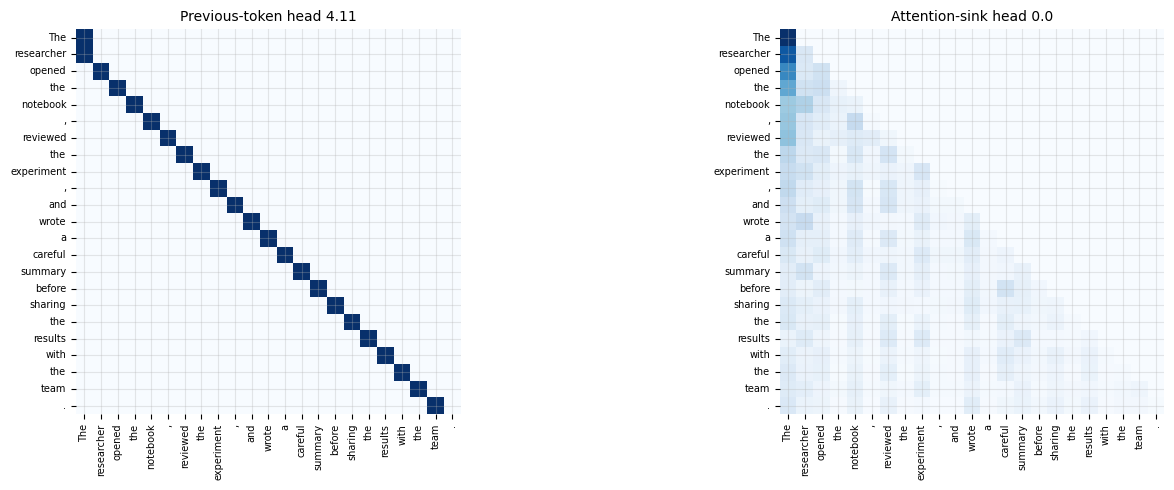

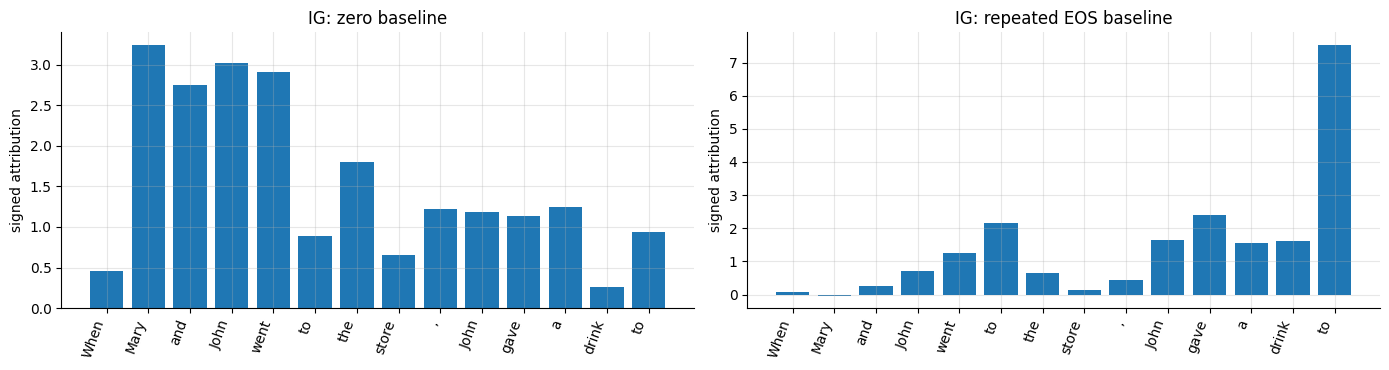

Top |IG| tokens, zero baseline: [' Mary', ' John', ' went', ' and', ' the']
Top |IG| tokens, EOS baseline: [' to', ' gave', ' to', ' John', ' drink']


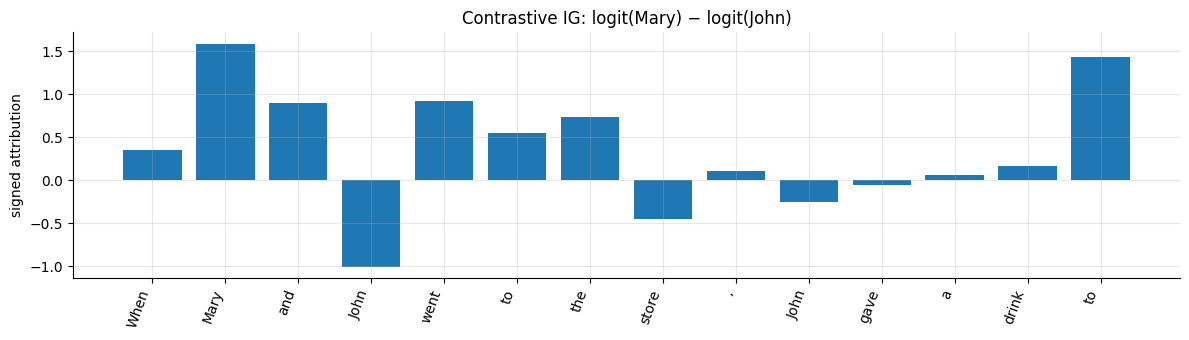

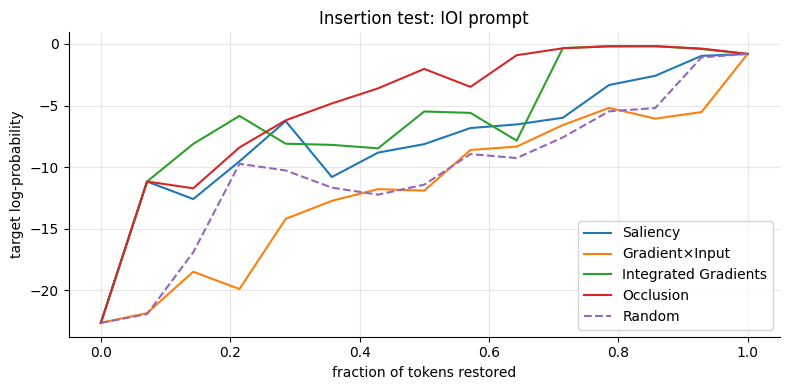

Target token: ' 71'


,layer,target_probability,target_rank
0,embed,2.469016e-21,35184
1,after L0,5.811132e-05,420
2,after L1,3.066440e-05,215
3,after L2,1.453626e-05,259
4,after L3,3.326575e-06,216
5,after L4,5.585552e-05,127
6,after L5,1.019996e-05,181
7,after L6,1.028087e-05,171
8,after L7,8.199822e-06,174
9,after L8,1.240150e-04,99


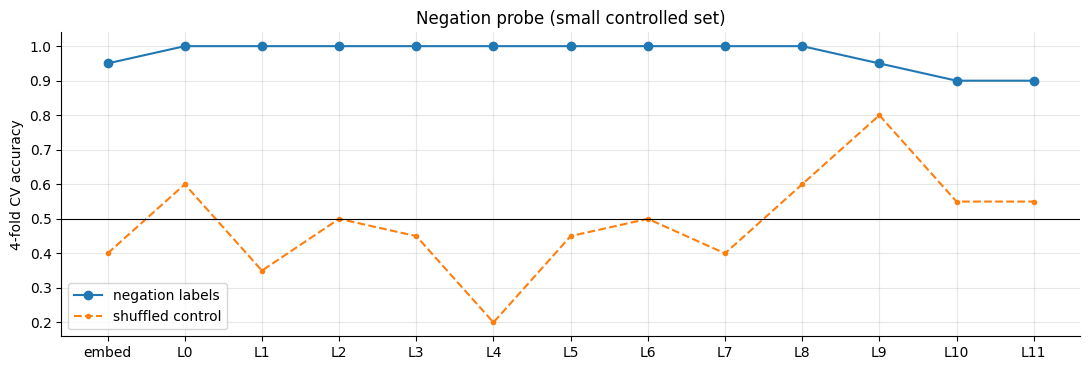

Peak negation probe accuracy: 1.0 at layer 1
Probe direction norm: 1.0 | layer: 1
This direction was trained for negation labels; sentiment score is only a secondary diagnostic, not a direct validation of negation steering.
Largest noising-direction effects: ['8.10 (+0.29)', '7.9 (+0.20)', '7.3 (+0.18)', '9.9 (+0.16)', '8.6 (+0.14)', '9.7 (+0.08)', '10.0 (+0.06)', '10.9 (+0.05)']


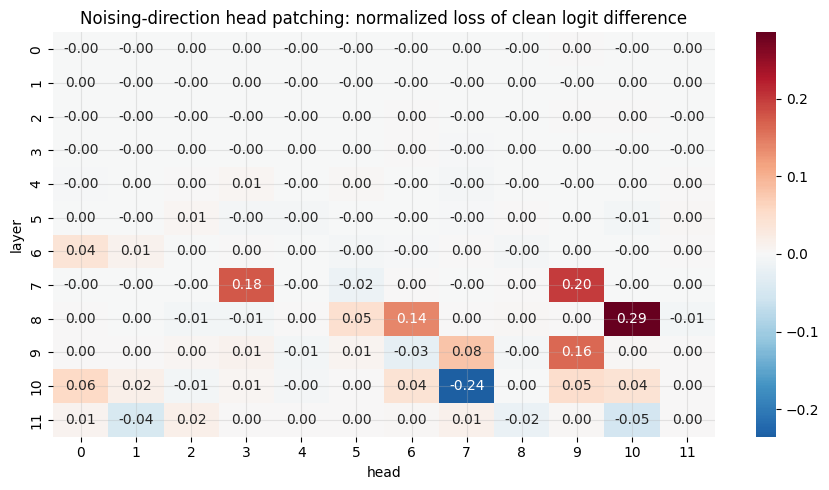

Head 9.9 mean-ablation logit difference: baseline=2.006, ablated=2.130, change=+0.124
Baseline second-copy loss: 0.4056
Mean-ablate induction head 5.5: second-copy loss=0.4019; increase=-0.0037
Mean-ablate induction head 6.9: second-copy loss=0.4340; increase=+0.0284
Mean-ablate induction head 7.10: second-copy loss=0.4088; increase=+0.0033


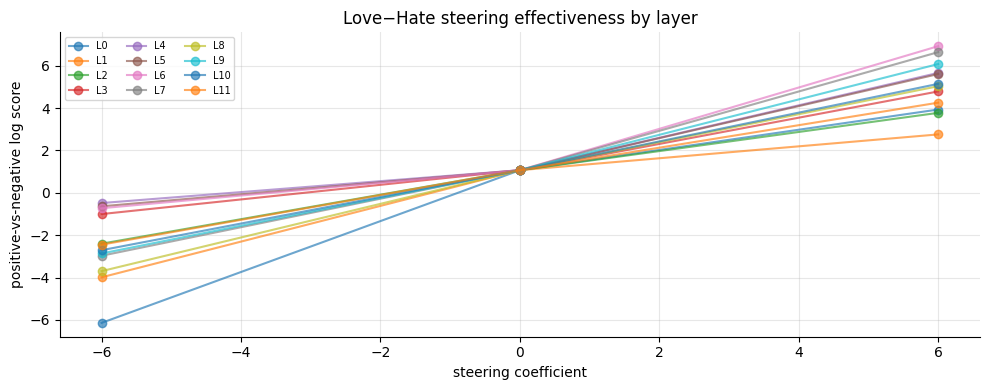

Most responsive steering layers: [0, 7, 9]
Single-pair direction scores: [-0.725, 1.07, 6.925]
Multi-pair direction scores: [-0.158, 1.07, 2.385]
Selected SAE feature: 181 | firing frequency: 0.1879
SAE feature contexts:

--- feature 181  (fires on 18.79% of tokens) ---
    3.84  …ne , a division of Penguin Books since[[ 1983]] , acquired…
    3.52  … the major cities of Thebes , Hel[[iop]]…
    3.31  … only to a maximum of + 5 to[[ +]] 7 °…
    3.24  … four songs , but only " There '[[s]] Got to…
    3.24  … gameplay despite annoying limitations to aspects such as[[ special]] abilities ,…
SAE feature steering scores: [1.062, 1.07, 1.077]


In [27]:
# Exercise solutions: run after the main notebook cells above.

# 2.1: a deliberately uncertain arithmetic prompt
FAIL_TEXT = "23 + 48 ="
print("Prompt:", FAIL_TEXT)
display(next_token_table(FAIL_TEXT, k=10))

# 3.1: rank previous-token heads and attention-sink heads, then plot on a longer sentence
sink_score = A[:, :, 1:, 0].mean(dim=(1, 3)).numpy()  # (layers, heads)
def rank_heads(scores, n=5):
    ix = np.argsort(-scores.ravel())[:n]
    return [(int(l), int(h), float(scores[l, h])) for l, h in
            zip(*np.unravel_index(ix, scores.shape))]
print("Top previous-token heads:", rank_heads(prev_score))
print("Top attention-sink heads:", rank_heads(sink_score))
custom_text = ("The researcher opened the notebook, reviewed the experiment, and wrote a careful summary "
               "before sharing the results with the team.")
custom_ids = to_ids(custom_text)
with torch.no_grad():
    custom_out = model(custom_ids, output_attentions=True)
custom_A = torch.stack(custom_out.attentions)[:, 0].cpu().numpy()
pl, ph, _ = rank_heads(prev_score, 1)[0]
sl, sh, _ = rank_heads(sink_score, 1)[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
custom_labels = labels(custom_ids)
plot_attention(custom_A[pl, ph], custom_labels, axes[0], f"Previous-token head {pl}.{ph}")
plot_attention(custom_A[sl, sh], custom_labels, axes[1], f"Attention-sink head {sl}.{sh}")
plt.tight_layout(); plt.show()

# 4.1: EOS embedding baseline for Integrated Gradients
ids_eos = to_ids(ioi_text)
target_mary = single_token_id(" Mary")
eos_baseline = embed(torch.full_like(ids_eos, tok.eos_token_id))
attrs_zero = integrated_gradients(ids_eos, target_mary, steps=32).detach().cpu().numpy()
attrs_eos = integrated_gradients(ids_eos, target_mary, baseline=eos_baseline, steps=32).detach().cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, vals, title in [(axes[0], attrs_zero, "IG: zero baseline"), (axes[1], attrs_eos, "IG: repeated EOS baseline")]:
    ax.bar(range(len(vals)), vals); ax.set_xticks(range(len(vals))); ax.set_xticklabels(labels(ids_eos), rotation=70, ha="right")
    ax.set_title(title); ax.set_ylabel("signed attribution")
plt.tight_layout(); plt.show()
print("Top |IG| tokens, zero baseline:", [tok_strs(ids_eos)[i] for i in np.argsort(-np.abs(attrs_zero))[:5]])
print("Top |IG| tokens, EOS baseline:", [tok_strs(ids_eos)[i] for i in np.argsort(-np.abs(attrs_eos))[:5]])

# 4.2: Integrated gradients for logit(Mary) - logit(John)
def contrastive_score(embeds, mary_id, john_id):
    logits = model(inputs_embeds=embeds).logits[:, -1, :]
    return logits[:, mary_id] - logits[:, john_id]
def contrastive_ig(ids, a_id, b_id, baseline=None, steps=32):
    x = token_embeds(ids)
    base = torch.zeros_like(x) if baseline is None else baseline
    alphas = (torch.arange(steps, device=x.device) + 0.5) / steps
    path = (base + alphas[:, None, None] * (x - base)).requires_grad_(True)
    grads, = torch.autograd.grad(contrastive_score(path, a_id, b_id).sum(), path)
    return ((x - base)[0] * grads.mean(0)).sum(-1).detach()
contrast_attrs = contrastive_ig(ids_eos, target_mary, single_token_id(" John")).cpu().numpy()
plt.figure(figsize=(12, 3.5)); plt.bar(range(len(contrast_attrs)), contrast_attrs)
plt.xticks(range(len(contrast_attrs)), labels(ids_eos), rotation=70, ha="right")
plt.title("Contrastive IG: logit(Mary) − logit(John)"); plt.ylabel("signed attribution")
plt.tight_layout(); plt.show()

# 5.1: insertion curve for the IOI prompt, using IG ranking
@torch.no_grad()
def insertion_curve(ids, target_id, order, baseline=None):
    x = token_embeds(ids)
    base = torch.zeros_like(x) if baseline is None else baseline
    T = x.shape[1]
    xs = base.repeat(T + 1, 1, 1)
    for k in range(1, T + 1):
        xs[k, order[:k]] = x[0, order[:k]]
    vals = target_logprob(xs, target_id).cpu().numpy()
    return vals
ids_ins, t_ins, attrs_ins = attribute(ioi_text, " Mary")
T_ins = ids_ins.shape[1]
plt.figure(figsize=(8, 4))
for method, a in attrs_ins.items():
    order = torch.as_tensor(np.argsort(-a).copy(), device=DEVICE)
    vals = insertion_curve(ids_ins, t_ins, order)
    plt.plot(np.arange(T_ins + 1) / T_ins, vals, label=method)
rand_order = torch.as_tensor(np.random.default_rng(SEED).permutation(T_ins), device=DEVICE)
plt.plot(np.arange(T_ins + 1) / T_ins, insertion_curve(ids_ins, t_ins, rand_order), label="Random", linestyle="--")
plt.xlabel("fraction of tokens restored"); plt.ylabel("target log-probability")
plt.title("Insertion test: IOI prompt"); plt.legend(); plt.tight_layout(); plt.show()

# 6.1: logit lens on the uncertain prompt; inspect target-token rank across layers
lens_ids, lens_probs = logit_lens(FAIL_TEXT)
# Arithmetic result is 71; GPT-2 may tokenize the leading-space string in more than one token.
answer_text = " 71"
answer_ids = tok(answer_text, add_special_tokens=False).input_ids
if len(answer_ids) == 1:
    aid = answer_ids[0]
    vals = lens_probs[:, -1, aid].numpy()
    ranks = np.array([(row.argsort(descending=True) == aid).nonzero()[0].item() + 1 for row in lens_probs[:, -1, :]])
    print("Target token:", repr(tok.decode([aid])))
    display(pd.DataFrame({"layer": LENS_LABELS, "target_probability": vals, "target_rank": ranks}))
else:
    print("The answer string tokenizes into multiple tokens; inspect the logit-lens plot for candidate continuations:", answer_ids)

# 7.1: controlled negation probe (positive vs negated wording)
NEGATION_PAIRS = [
    ("This is good.", 0), ("This is not good.", 1),
    ("The result is useful.", 0), ("The result is not useful.", 1),
    ("The plan seems safe.", 0), ("The plan does not seem safe.", 1),
    ("That answer is correct.", 0), ("That answer is not correct.", 1),
    ("The solution works.", 0), ("The solution does not work.", 1),
    ("The claim is valid.", 0), ("The claim is not valid.", 1),
    ("This approach is effective.", 0), ("This approach is not effective.", 1),
    ("The explanation is clear.", 0), ("The explanation is not clear.", 1),
    ("The method is reliable.", 0), ("The method is not reliable.", 1),
    ("The outcome is expected.", 0), ("The outcome is not expected.", 1),
]
neg_texts = [x for x, _ in NEGATION_PAIRS]
neg_y = np.array([y for _, y in NEGATION_PAIRS])
neg_last, neg_mean = sentence_reps(neg_texts)
neg_cv = StratifiedKFold(4, shuffle=True, random_state=SEED)
neg_probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
neg_acc = [cross_val_score(neg_probe, neg_last[:, l], neg_y, cv=neg_cv).mean() for l in range(neg_last.shape[1])]
neg_control = [cross_val_score(neg_probe, neg_last[:, l], np.random.default_rng(SEED+l).permutation(neg_y), cv=neg_cv).mean()
               for l in range(neg_last.shape[1])]
plt.figure(figsize=(11, 3.8)); plt.plot(["embed"]+[f"L{i}" for i in range(N_LAYERS)], neg_acc, marker="o", label="negation labels")
plt.plot(["embed"]+[f"L{i}" for i in range(N_LAYERS)], neg_control, marker=".", linestyle="--", label="shuffled control")
plt.axhline(0.5, color="black", linewidth=.8); plt.ylabel("4-fold CV accuracy"); plt.title("Negation probe (small controlled set)")
plt.legend(); plt.tight_layout(); plt.show()
print("Peak negation probe accuracy:", round(float(max(neg_acc)), 3), "at layer", int(np.argmax(neg_acc)))

# 7.2: use a fitted mid-layer probe coefficient as a residual-stream intervention direction
PROBE_STEER_LAYER = int(np.argmax(neg_acc))
neg_probe.fit(neg_last[:, PROBE_STEER_LAYER], neg_y)
probe_direction = torch.tensor(neg_probe[-1].coef_[0], dtype=torch.float32, device=DEVICE)
probe_direction = probe_direction / (probe_direction.norm() + 1e-8)
print("Probe direction norm:", float(probe_direction.norm()), "| layer:", PROBE_STEER_LAYER)
print("This direction was trained for negation labels; sentiment score is only a secondary diagnostic, not a direct validation of negation steering.")

# 8.1: noising direction — insert corrupted head activations into clean run
@torch.no_grad()
def noised_head_run(ids, corrupt_cache, layer, head, pos=-1):
    cols = slice(head * D_HEAD, (head + 1) * D_HEAD)
    def pre_hook(mod, args):
        z = args[0].clone()
        z[:, pos, cols] = corrupt_cache[layer][:, pos, cols]
        return (z,) + tuple(args[1:])
    handle = model.transformer.h[layer].attn.c_proj.register_forward_pre_hook(pre_hook)
    try:
        return model(ids).logits
    finally:
        handle.remove()
corrupt_heads = run_with_head_cache(corrupt_ids)
noising_drop = np.zeros((N_LAYERS, N_HEADS))
for ll in range(N_LAYERS):
    for hh in range(N_HEADS):
        patched_ld = logit_diff(noised_head_run(clean_ids, corrupt_heads, ll, hh))
        noising_drop[ll, hh] = (LD_CLEAN - patched_ld) / (LD_CLEAN - LD_CORRUPT)
print("Largest noising-direction effects:", [f"{l}.{h} ({noising_drop[l,h]:+.2f})" for l,h,_ in rank_heads(noising_drop, 8)])
plt.figure(figsize=(9, 5)); sns.heatmap(noising_drop, center=0, cmap="RdBu_r", annot=True, fmt=".2f")
plt.title("Noising-direction head patching: normalized loss of clean logit difference")
plt.xlabel("head"); plt.ylabel("layer"); plt.tight_layout(); plt.show()

# 8.2: mean-ablate head 9.9 across a small set of IOI prompts (if token lengths align)
def mean_ablate_head_logit_diff(text, layer=9, head=9, n_variants=8):
    prompts = [
        "When Mary and John went to the store, John gave a drink to",
        "When Alice and Bob went to the store, Bob gave a drink to",
        "When Sarah and Tom went to the store, Tom gave a drink to",
        "When Anna and Peter went to the store, Peter gave a drink to",
    ]
    cache_list = []
    for p in prompts:
        ids_p = to_ids(p)
        cache_list.append(run_with_head_cache(ids_p)[layer][:, -1, head*D_HEAD:(head+1)*D_HEAD].mean(0))
    mean_act = torch.stack(cache_list).mean(0)
    def hook(mod, args):
        z = args[0].clone(); z[:, -1, head*D_HEAD:(head+1)*D_HEAD] = mean_act
        return (z,) + tuple(args[1:])
    ids0 = to_ids(text)
    handle = model.transformer.h[layer].attn.c_proj.register_forward_pre_hook(hook)
    try:
        logits = model(ids0).logits
    finally:
        handle.remove()
    # For the canonical prompt, Mary/John is a valid contrast. For variants, the contrast must be changed accordingly.
    return logit_diff(logits)
try:
    baseline_ld = logit_diff(model(clean_ids).logits)
    ablated_ld = mean_ablate_head_logit_diff(clean_text)
    print(f"Head 9.9 mean-ablation logit difference: baseline={baseline_ld:.3f}, ablated={ablated_ld:.3f}, change={ablated_ld-baseline_ld:+.3f}")
except Exception as e:
    print("Mean-ablation experiment could not complete in this runtime:", repr(e))

# 9.1: induction head ablation on the repeated random-token batch
# Compute baseline loss for second-copy targets, then replace each candidate head's output
# with its mean across batch at each sequence position.
def second_copy_loss(logits, ids, n=N_REP):
    lp = logits.log_softmax(-1)
    # token at position j is predicted by logits at j-1
    target_logits = lp[:, n:2*n, :]
    target_ids = ids[:, n+1:2*n+1]
    return -target_logits.gather(-1, target_ids.unsqueeze(-1)).mean().item()
baseline_second_loss = second_copy_loss(model(rep_ids).logits, rep_ids)
print("Baseline second-copy loss:", round(baseline_second_loss, 4))
for ll, hh in top_heads[:3]:
    # Cache concatenated head outputs for the batch, then mean across batch at every sequence position.
    cache = {}
    def pre(mod, args, ll=ll):
        cache[ll] = args[0].detach().clone()
    handle = model.transformer.h[ll].attn.c_proj.register_forward_pre_hook(pre)
    try:
        _ = model(rep_ids)
    finally:
        handle.remove()
    mean_z = cache[ll][:, :, hh*D_HEAD:(hh+1)*D_HEAD].mean(0, keepdim=True)
    def ablate_hook(mod, args, hh=hh, mean_z=mean_z):
        z = args[0].clone(); z[:, :, hh*D_HEAD:(hh+1)*D_HEAD] = mean_z.expand(z.shape[0], -1, -1)
        return (z,) + tuple(args[1:])
    handle = model.transformer.h[ll].attn.c_proj.register_forward_pre_hook(ablate_hook)
    try:
        loss_ab = second_copy_loss(model(rep_ids).logits, rep_ids)
    finally:
        handle.remove()
    print(f"Mean-ablate induction head {ll}.{hh}: second-copy loss={loss_ab:.4f}; increase={loss_ab-baseline_second_loss:+.4f}")

# 10.1: layer sweep using the existing Love-Hate vector at each layer
layer_scores = {}
for layer in range(N_LAYERS):
    vec = resid_entering(" Love", layer) - resid_entering(" Hate", layer)
    vals = []
    for coef in [-6, 0, 6]:
        handle = add_steering(vec, layer, coef) if coef else None
        try:
            scores_here = []
            for p in STEER_PROMPTS:
                lp = model(to_ids(p)).logits[0, -1].log_softmax(-1)
                scores_here.append((lp[POS_W].logsumexp(0) - lp[NEG_W].logsumexp(0)).item())
            vals.append(float(np.mean(scores_here)))
        finally:
            if handle is not None: handle.remove()
    layer_scores[layer] = vals
plt.figure(figsize=(10, 4))
for layer, vals in layer_scores.items():
    plt.plot([-6, 0, 6], vals, marker="o", alpha=.65, label=f"L{layer}")
plt.xlabel("steering coefficient"); plt.ylabel("positive-vs-negative log score")
plt.title("Love−Hate steering effectiveness by layer"); plt.legend(ncol=3, fontsize=7); plt.tight_layout(); plt.show()
layer_effect = {l: abs(v[2]-v[0]) for l,v in layer_scores.items()}
print("Most responsive steering layers:", sorted(layer_effect, key=layer_effect.get, reverse=True)[:3])

# 10.2: multi-pair direction from the Section 7 sentiment corpus
PAIR_POS = ["I loved the movie.", "The meal was wonderful.", "The experience was delightful.", "I feel happy today.",
            "The result was excellent.", "The service was friendly."]
PAIR_NEG = ["I hated the movie.", "The meal was terrible.", "The experience was awful.", "I feel sad today.",
            "The result was disappointing.", "The service was rude."]
PAIR_LAYER = 6
pos_rep, _ = sentence_reps(PAIR_POS)
neg_rep, _ = sentence_reps(PAIR_NEG)
multi_vec = torch.tensor((pos_rep[:, PAIR_LAYER].mean(0)-neg_rep[:, PAIR_LAYER].mean(0)), dtype=torch.float32, device=DEVICE)
multi_vec = multi_vec / (multi_vec.norm() + 1e-8)
single_vec = resid_entering(" Love", PAIR_LAYER) - resid_entering(" Hate", PAIR_LAYER)
def score_with_vec(vec, layer, coef):
    handle = add_steering(vec, layer, coef) if coef else None
    try:
        vals=[]
        for p in STEER_PROMPTS:
            lp=model(to_ids(p)).logits[0,-1].log_softmax(-1)
            vals.append((lp[POS_W].logsumexp(0)-lp[NEG_W].logsumexp(0)).item())
        return float(np.mean(vals))
    finally:
        if handle is not None: handle.remove()
print("Single-pair direction scores:", [round(score_with_vec(single_vec, PAIR_LAYER, c),3) for c in [-6,0,6]])
print("Multi-pair direction scores:", [round(score_with_vec(multi_vec, PAIR_LAYER, c),3) for c in [-6,0,6]])

# 11.1: steer with an SAE decoder feature. Select a readable feature index after inspecting show_feature output.
# Set FEATURE_ID to an interpretable feature from the list printed in Section 11.
FEATURE_ID = int(np.argmax(freq))
feature_vec = sae.W_dec[FEATURE_ID].detach()
# Compare target sentiment score for small coefficients. Treat the outcome as exploratory.
print("Selected SAE feature:", FEATURE_ID, "| firing frequency:", round(float(freq[FEATURE_ID]), 4))
print("SAE feature contexts:")
show_feature(FEATURE_ID, k=5)
print("SAE feature steering scores:", [round(score_with_vec(feature_vec, SAE_LAYER, c),3) for c in [-2,0,2]])
